# D7. Whisper 심층 분석: 구조 · 모델 크기 · 언어 감지 · 디코딩 옵션 · 환각 대응

**음성 AI 전문가 과정 (160h) | 2주차 M2 | 4시간**

## 학습 목표
1. Whisper가 음성을 **30초 창 → Log-Mel → Encoder(귀) → Decoder(손)** 순서로 처리한다는 것을 그림으로 설명하고, **특수 토큰(지시문)** 으로 언어와 작업을 바꿀 수 있다.
2. tiny부터 large-v3 · turbo까지 **모델 크기에 따른 속도와 정확도의 교환 관계**를 직접 재고(RTF, CER), 상황에 맞는 모델을 고를 수 있다.
3. Whisper가 **언어를 알아내는 방법**(첫 토큰 확률)을 확인하고, 받아쓰기와 **영어 번역**을 바꿔 실행한다.
4. **greedy · beam search · temperature · 타임스탬프 · 프롬프트** 등 디코딩 옵션이 결과에 주는 영향을 비교한다.
5. 무음 · 반복 같은 **환각(hallucination)** 을 직접 만들어 보고, **VAD · 무음 확률 · 압축률 · temperature fallback** 으로 막는다.

## 오늘의 실습 흐름
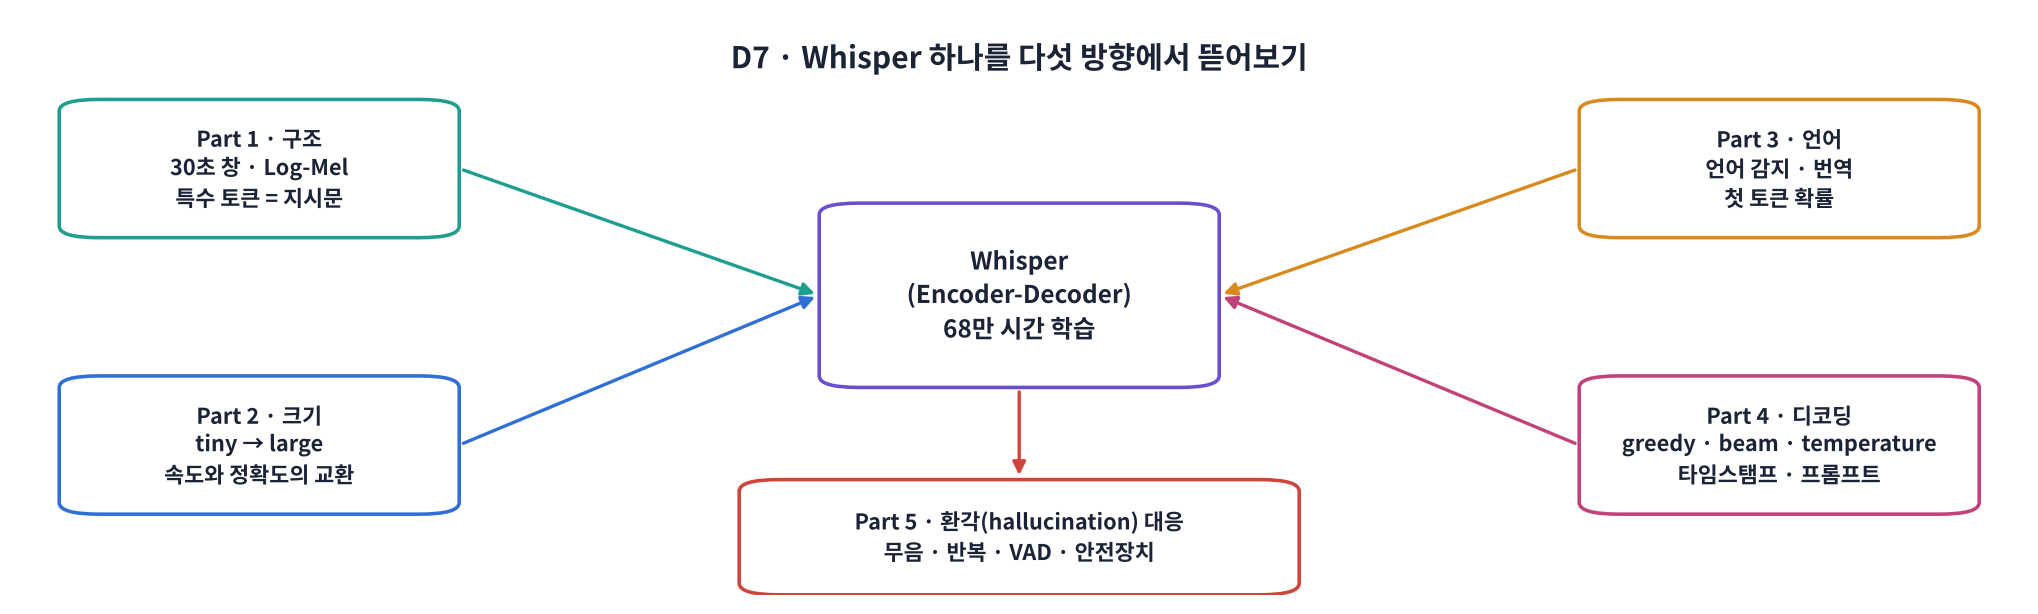

| 교시 | 내용 | 실습 |
|---|---|---|
| 1교시 | Whisper 구조: 30초 창, Log-Mel, Encoder · Decoder, 특수 토큰 | Part 0 ~ 1, 워크시트 1교시 |
| 2교시 | 모델 크기별 속도 · 정확도(RTF, CER), 언어 감지, 번역 | Part 2 ~ 3, 워크시트 2교시 |
| 3교시 | 디코딩 옵션: greedy vs beam, temperature, 타임스탬프, 프롬프트 | Part 4, 워크시트 3교시 |
| 4교시 | 환각 만들기와 막기: 무음 확률, 압축률, 안전장치, VAD | Part 5 ~ 6, 워크시트 4교시 · 노션 제출 |

## 오늘의 수업 자료
| 자료 | 링크 | 언제 쓰나요 |
|---|---|---|
| 🎬 인터랙티브 애니메이션 | [animation.html](https://imguru-mooc.github.io/AI_Voice/day07/animation.html) | 각 Part 설명을 볼 때 (Part마다 바로가기 링크가 있습니다) |
| 📝 개념 워크시트 | [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day07/worksheet.html) | 각 교시 끝에 해당 탭 10문항 (4교시 × 10문항), 오답 캡처 → 노션 |

## 이 노트북 사용법
- ▶️ 일반 코드 셀은 위에서부터 차례로 실행합니다.
- 🧩 **빈칸 실습** 셀은 `____`(밑줄 4개)를 지우고 알맞은 값을 채운 뒤 실행합니다. 마지막 줄에서 ✅ 또는 ❌로 결과를 알려줍니다. 🔑 **정답 및 해설 보기**를 클릭하면 정답이 펼쳐집니다.
- 오늘은 **수식보다 그림과 말로** 설명합니다. 설명은 아래 표시를 따라 읽으세요.

| 표시 | 뜻 |
|---|---|
| 💬 **쉽게 말하면** | 그 절의 내용을 한 문장으로 |
| 🍎 **비유** | 일상의 장면으로 바꿔 보기 |
| 👣 **한 단계씩** | 무슨 일이 어떤 순서로 일어나는지 |
| 📐 **핵심 식 하나** | 꼭 필요한 식 하나와 "읽는 법" |
| ❓ **생각해 보기** | 스스로 답해 보고 펼쳐서 확인 |
| 🔍 **코드 해설** | 주요 코드를 한 줄씩 |

> ⚙️ **GPU 런타임을 권장합니다** ([런타임] → [런타임 유형 변경] → **T4 GPU**). CPU에서도 돌아가지만 Part 2의 모델 비교가 느리고, 가장 큰 모델(turbo)은 GPU에서만 비교합니다. 처음 실행할 때 모델(합계 약 1~3 GB)을 내려받습니다.

> 🎬 **애니메이션 D7-1:** [오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day07/animation.html#flow) — Part 1~5 로드맵

## Part 0. 준비

`transformers`, `torch`, `librosa`는 Colab에 이미 있습니다. 시험 음성을 만들 **gTTS**, 글자 오류율을 잴 **jiwer**, 4교시에 쓸 **silero-vad**(D4에서 쓴 VAD)만 설치합니다.

In [ ]:
!pip install -q gTTS jiwer silero-vad
print("✅ 설치 완료")

In [ ]:
import os, time, zlib, math, re, random
import numpy as np
import librosa, librosa.display
import matplotlib.pyplot as plt
import torch
import jiwer
from IPython.display import Audio, display
from gtts import gTTS
from transformers import WhisperProcessor, WhisperForConditionalGeneration

SR = 16000
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32      # GPU에서는 반정밀도로 빠르게
torch.manual_seed(0); np.random.seed(0); random.seed(0)

def check(cond, hint="빈칸을 다시 확인하세요."):
    print("✅ 정답입니다! 🎉" if cond else f"❌ {hint}")

print(f"torch {torch.__version__} | device = {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else " (CPU: 모델 비교는 작은 모델만)"))

In [ ]:
# 오늘의 시험 음성: gTTS로 문장을 합성해 16 kHz mono로 읽기 (앞뒤 무음은 D4처럼 잘라 냄)
def tts(text, path, lang="ko"):
    gTTS(text, lang=lang).save(path)
    y, _ = librosa.load(path, sr=SR, mono=True)
    y, _ = librosa.effects.trim(y, top_db=35)
    return y.astype(np.float32)

TEXTS = {
    "ko":       ("안녕하세요. 오늘은 음성 인식 모델 위스퍼를 자세히 알아보겠습니다.", "ko"),
    "ko_terms": ("아이구루 교육센터에서 라이브킷과 파이프캣으로 음성 에이전트를 만듭니다.", "ko"),
    "en":       ("Whisper was trained on six hundred eighty thousand hours of audio.", "en"),
    "ja":       ("今日はいい天気ですね。散歩に行きましょう。", "ja"),
    "mix":      ("오늘 meeting은 three o'clock에 시작하고 agenda는 이메일로 보내 드릴게요.", "ko"),
}
audio = {k: tts(t, f"{k}.mp3", lang) for k, (t, lang) in TEXTS.items()}
for k, y in audio.items():
    print(f"{k:9s} {len(y) / SR:4.1f}초 | {TEXTS[k][0]}")
display(Audio(audio["ko"], rate=SR))

In [ ]:
# 오늘의 기본 모델: whisper-small (2억 4천만 파라미터, 한국어도 꽤 잘함)
MAIN = "openai/whisper-small"
proc = WhisperProcessor.from_pretrained(MAIN)
model = WhisperForConditionalGeneration.from_pretrained(MAIN, dtype=DTYPE, attn_implementation="eager").to(DEVICE).eval()
tok = proc.tokenizer

def feats_of(y, p=proc, m=model):
    # 파형 → Log-Mel (30초 창) → 모델과 같은 장치 · 자료형으로
    return p(y, sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE, m.dtype)

def transcribe(y, m=model, p=proc, **kw):
    # 30초 이하 음성 한 개를 받아 적어 문자열로 돌려줌. kw = generate() 옵션 (language, task, num_beams, ...)
    with torch.no_grad():
        out = m.generate(feats_of(y, p, m), **kw)
    return p.tokenizer.batch_decode(out, skip_special_tokens=True)[0].strip()

print(f"{MAIN}: 파라미터 {sum(x.numel() for x in model.parameters()) / 1e6:.0f}M")
print("받아쓰기:", transcribe(audio["ko"], language="ko"))

#### 🔍 코드 해설: 오늘 계속 쓰는 두 함수

| 코드 | 하는 일 |
|---|---|
| `WhisperProcessor` | **특징 추출기**(파형 → 30초 Log-Mel)와 **토크나이저**(글자 ↔ 번호)를 하나로 묶은 것. D6의 Wav2Vec2Processor와 같은 역할 |
| `dtype=torch.float16` | GPU에서 숫자를 반 크기로 저장 → 메모리 절반, 속도 향상. 정확도는 거의 같음 |
| `attn_implementation="eager"` | attention 가중치를 꺼내 볼 수 있는 방식. 오늘은 내부를 들여다보므로 이걸 씀 |
| `feats_of(y)` | 파형 → `input_features` (1, 80, 3000) |
| `transcribe(y, language="ko")` | `generate()`로 받아 적고 특수 토큰을 빼서 문장만 돌려줌. 뒤에 붙이는 옵션이 **오늘의 주인공** |

## Part 1. Whisper의 구조: 귀가 듣고, 손이 받아 적는다

> 💬 **쉽게 말하면**: Whisper는 **D6에서 배운 Attention Encoder-Decoder**입니다. 귀(Encoder)가 30초 분량의 소리를 한 번에 듣고 요약해 두면, 손(Decoder)이 그 요약을 들여다보며 글자를 한 토큰씩 적습니다.

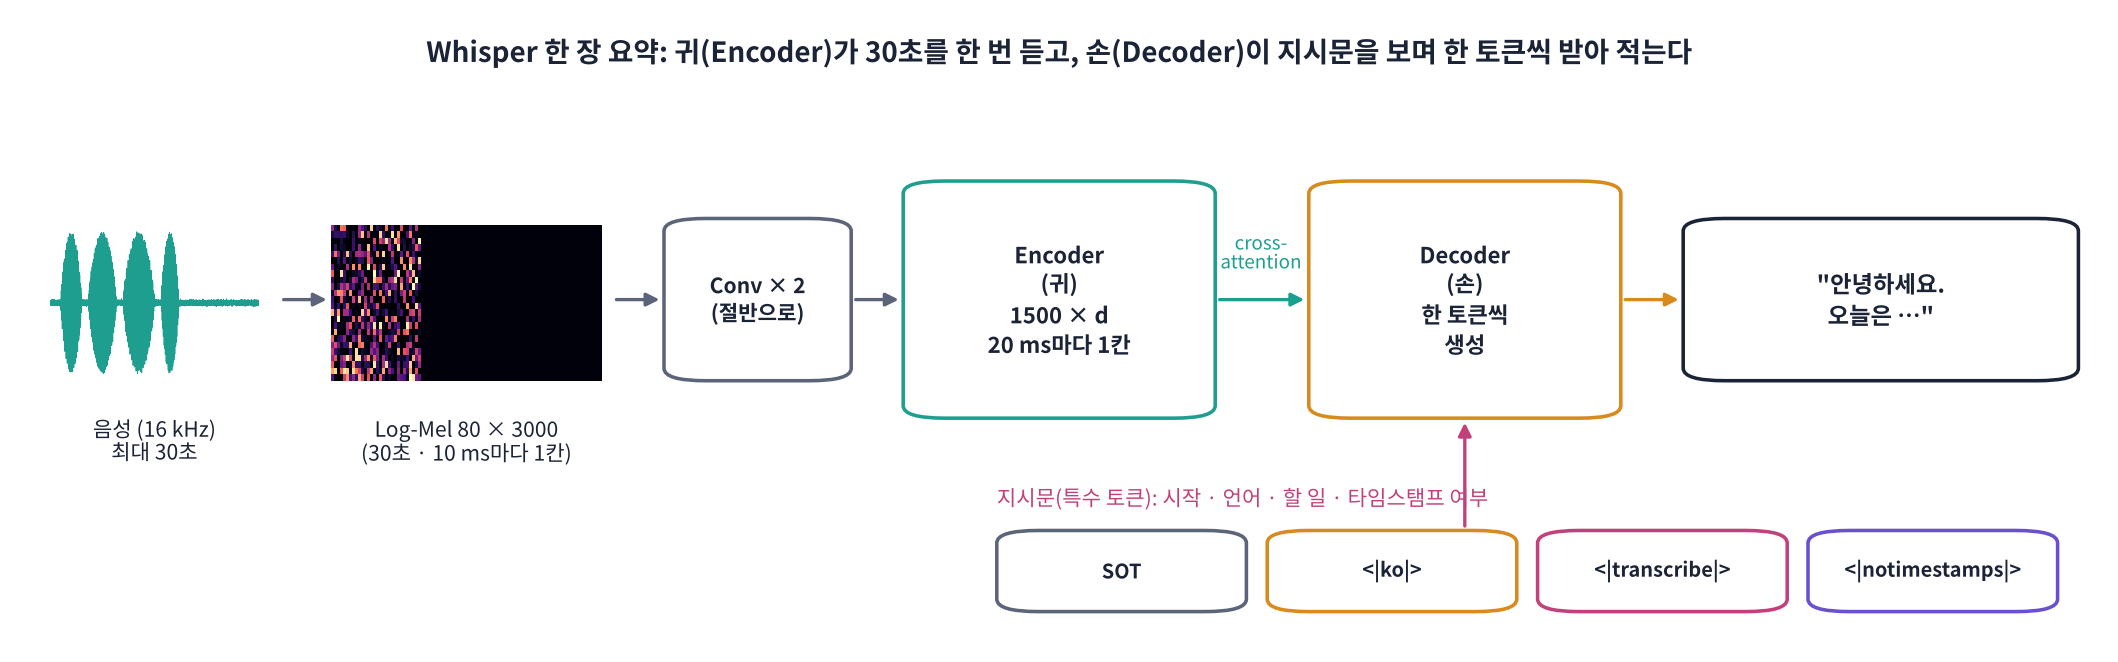

> 🍎 **비유: 통역 부스의 두 사람**
> - **귀 담당(Encoder)**: 30초짜리 녹음을 처음부터 끝까지 듣고, 20 ms마다 메모 한 줄(총 1500줄)을 남깁니다. 한 번만 듣습니다.
> - **손 담당(Decoder)**: 메모를 보면서 받아쓰기를 합니다. 한 글자(토큰)를 쓸 때마다 "지금까지 쓴 것"과 "메모의 어느 부분"을 함께 봅니다(D6의 cross-attention).
> - **주문서(특수 토큰)**: 손 담당에게 "한국어로 · 받아 적어 · 시각은 표시하지 마" 같은 지시를 맨 앞에 적어 줍니다.

**Whisper가 특별한 이유**: 구조는 평범한 Transformer입니다. 특별한 것은 **데이터**입니다. 인터넷에서 모은 **68만 시간**(large-v3는 약 500만 시간)의 "음성 + 자막" 쌍으로 학습했습니다. 자막이 사람이 다듬은 것만은 아니라서 '약한 지도 학습(weak supervision)'이라고 부릅니다. 덕분에 99개 언어를 알아듣지만, **자막에 흔한 문장을 지어내는 습관(환각)** 도 함께 배웠습니다. 이 습관이 4교시 주제입니다.

> 🎬 **애니메이션 D7-2:** [30초 창과 구조](https://imguru-mooc.github.io/AI_Voice/day07/animation.html#arch) — 음성 길이를 바꿔 패딩 · 잘라 넣기, Log-Mel 3000칸 → Encoder 1500칸

### 1-1. 30초 창: 짧으면 채우고, 길면 자른다

> 💬 **쉽게 말하면**: Whisper는 **항상 정확히 30초**를 입력으로 받습니다. 3초짜리를 넣으면 뒤 27초를 0(무음)으로 채우고, 70초짜리는 30초씩 잘라 차례로 넣습니다.

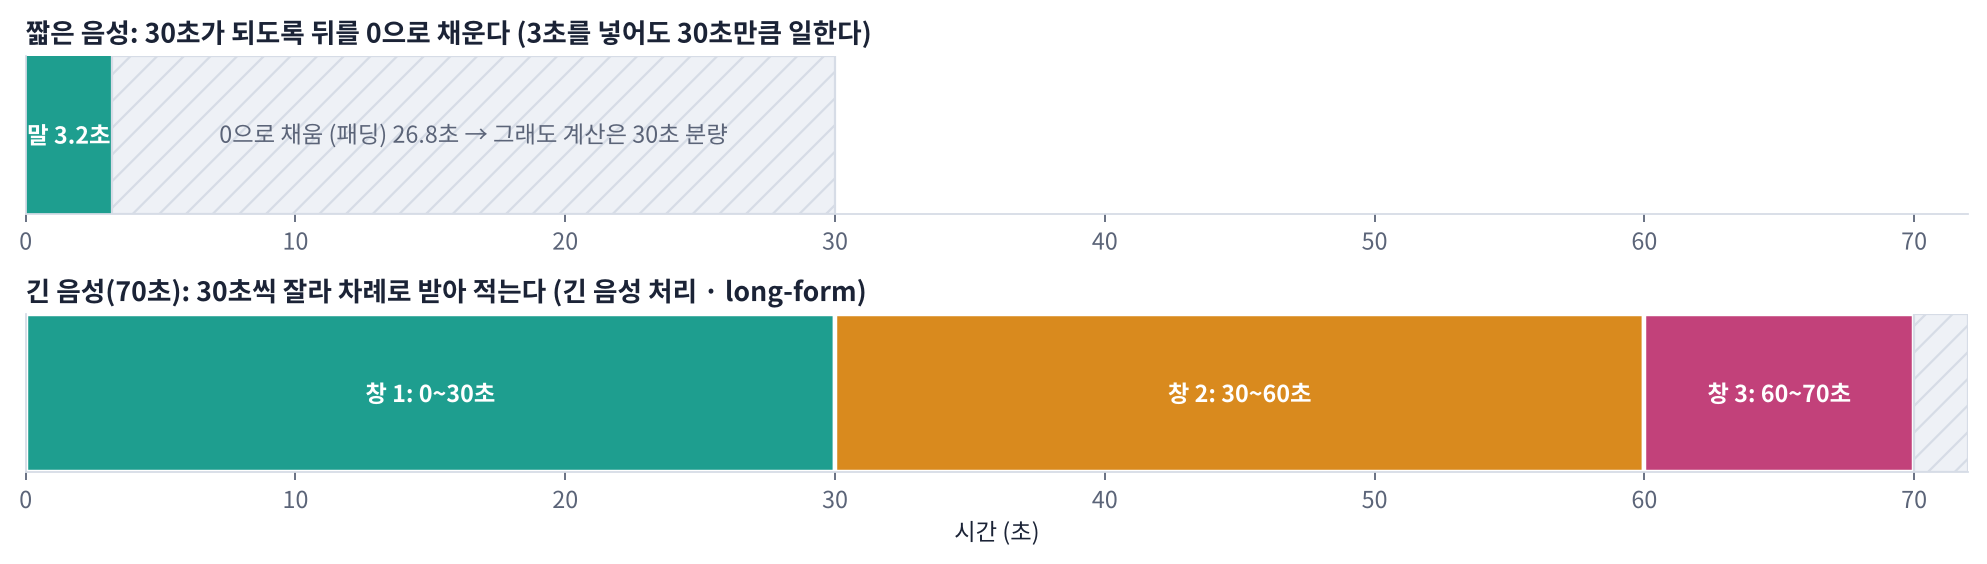

👣 **한 단계씩**
1. 음성 길이를 **16,000 × 30 = 480,000 샘플**로 맞춥니다 (짧으면 0으로 채움 = 패딩).
2. 10 ms마다 한 칸씩 Log-Mel을 계산합니다 (D3과 같은 25 ms 창, 10 ms 간격) → 가로 **3000칸**, 세로 **80칸**(large-v3 · turbo는 128칸).
3. 이 (80 × 3000) 그림이 Encoder의 입력입니다.

왜 30초로 고정했을까요? 학습할 때 자막을 30초 단위로 잘라 썼기 때문입니다. 길이가 늘 같으면 배치로 묶기 쉽고 구조가 단순해집니다. 대신 **3초를 넣어도 30초만큼 계산**하는 손해가 있습니다(1-2에서 직접 확인).

### 🧩 빈칸 실습 1: 30초 창의 크기
Whisper 창의 길이(초)를 넣으세요. 특징 추출기가 쓰는 값(`n_samples`)과 같아야 합니다.

In [ ]:
# 🧩 빈칸 실습 1
CHUNK_SEC = ____                                    # Whisper 창의 길이 (초)
N_SAMPLES = CHUNK_SEC * SR

y = audio["ko"]
padded = np.pad(y, (0, N_SAMPLES - len(y)))         # 뒤를 0으로 채워 30초로
f = proc(y, sampling_rate=SR, return_tensors="pt").input_features
print(f"원래 길이 {len(y) / SR:.1f}초 → 채운 뒤 {len(padded) / SR:.0f}초 ({len(padded):,} 샘플)")
print(f"특징 추출기 기준: n_samples = {proc.feature_extractor.n_samples:,}, 입력 모양 {tuple(f.shape)} (배치, mel 칸, 시간 칸)")

fig, axs = plt.subplots(2, 1, figsize=(13, 4.2), sharex=True)
t = np.arange(len(padded)) / SR
axs[0].plot(t, padded, lw=0.4, color="tab:cyan"); axs[0].axvspan(len(y) / SR, 30, color="gray", alpha=0.15)
axs[0].set_title("waveform padded to 30 s (gray = zeros)")
axs[1].imshow(f[0].numpy(), origin="lower", aspect="auto", cmap="magma", extent=[0, 30, 0, f.shape[1]])
axs[1].set_title(f"Log-Mel {f.shape[1]} x {f.shape[2]} (10 ms per column)"); axs[1].set_xlabel("time (s)")
plt.tight_layout(); plt.show()
check(N_SAMPLES == proc.feature_extractor.n_samples and f.shape[-1] == N_SAMPLES // 160, hint="Whisper는 30초 단위로 일합니다.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
CHUNK_SEC = 30
```

**해설**: 16,000 × 30 = 480,000 샘플이고, 10 ms(160 샘플)마다 한 칸이므로 480,000 ÷ 160 = **3000칸**입니다. 그림 아래쪽 Log-Mel에서 말이 있는 앞부분만 밝고 나머지 27초는 거의 검은색(무음)인 것을 보세요. Whisper는 이 검은 부분까지 다 계산합니다.

</details>

### 1-2. Encoder: 3000칸을 1500칸으로 요약하는 '귀'

> 💬 **쉽게 말하면**: Encoder는 맨 앞의 합성곱 2개 중 하나가 **보폭 2**라서 3000칸을 **1500칸**으로 줄입니다. 한 칸이 **20 ms** 분량이 됩니다(D6의 Wav2Vec2 프레임과 같은 간격).

👣 **한 단계씩**
1. Conv 1 (보폭 1): 80칸 → d칸으로 바꾸기만, 길이 3000 그대로
2. Conv 2 (**보폭 2**): 길이 3000 → **1500**
3. Transformer 층(small은 12층): 1500칸이 서로를 보며(self-attention) 문맥을 섞음
4. 결과: (1500 × d) 메모. small은 d = 768

아래 셀은 **3초짜리**와 **25초짜리**를 넣었을 때 Encoder 시간이 거의 같은지 잽니다. 둘 다 30초로 채워지기 때문입니다.

In [ ]:
# ▶️ 확인: Encoder 출력 모양, 그리고 '짧은 음성도 30초만큼 일한다'
long25 = np.tile(audio["ko"], int(np.ceil(25 * SR / len(audio["ko"]))))[: 25 * SR]

def encoder_time(y, n=3):
    f = feats_of(y)
    with torch.no_grad():
        model.model.encoder(f)                                  # 워밍업
        if DEVICE == "cuda": torch.cuda.synchronize()
        t0 = time.time()
        for _ in range(n):
            h = model.model.encoder(f).last_hidden_state
        if DEVICE == "cuda": torch.cuda.synchronize()
    return (time.time() - t0) / n, h.shape

for name, y in [("3초 음성", audio["ko"]), ("25초 음성", long25)]:
    sec, shape = encoder_time(y)
    print(f"{name:8s}: 실제 {len(y) / SR:4.1f}초 → Encoder 출력 {tuple(shape)}, 시간 {sec * 1000:6.1f} ms")
print("→ 출력 모양도 시간도 거의 같습니다. 짧은 음성이 많다면 낭비가 큰 구조입니다 (D8에서 다룹니다).")

**❓ 생각해 보기**: 1분짜리 회의 녹음을 Whisper에 그대로(자르지 않고) 넣으면 어떻게 될까요?

<details>
<summary>답 보기</summary>

`proc(...)`가 기본으로 **앞 30초만 남기고 잘라 버립니다**(truncation). 뒤 30초는 받아 적지 않습니다. 긴 음성은 30초씩 나눠 넣는 **long-form 처리**가 필요합니다. 4교시 5-4에서 `truncation=False`로 긴 음성을 통째로 넣는 방법을 씁니다.

</details>

### 1-3. 특수 토큰: Decoder에게 주는 주문서

> 💬 **쉽게 말하면**: Decoder의 맨 앞 4칸은 **받아 쓴 내용이 아니라 지시문**입니다. 이 지시문을 바꾸면 같은 모델이 다른 언어, 번역, 타임스탬프 출력까지 해냅니다.

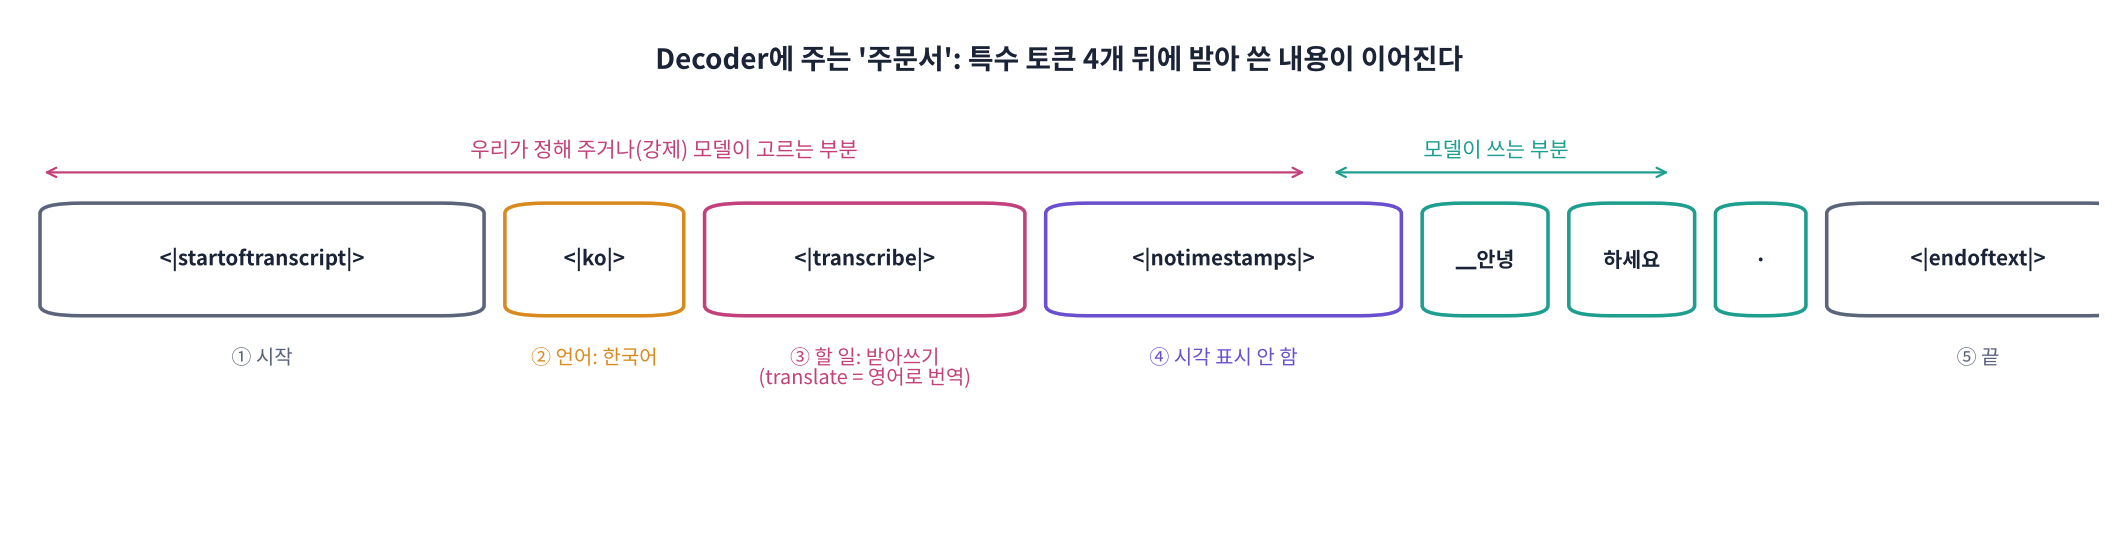

| 순서 | 토큰 | 뜻 | 바꾸면? |
|---|---|---|---|
| ① | `<|startoftranscript|>` | 시작 (SOT) | 항상 고정 |
| ② | `<|ko|>`, `<|en|>`, … (99개) | 이 음성의 언어 | 비워 두면 **모델이 스스로 고름** = 언어 감지 (Part 3) |
| ③ | `<|transcribe|>` / `<|translate|>` | 할 일: 받아쓰기 / **영어로 번역** | translate로 바꾸면 한국어 음성 → 영어 문장 |
| ④ | `<|notimestamps|>` | 시각 표시 안 함 | 빼면 `<|0.00|>` 같은 **시각 토큰**이 문장 사이에 끼어 나옴 (Part 4) |
| ⑤ | `<|endoftext|>` | 끝 | 모델이 스스로 씀 |

🍎 **비유**: 식당 주문서 맨 위에 "포장 · 매운맛 · 수저 빼고"를 적는 것과 같습니다. 요리사(Decoder)는 그 지시를 보고 같은 재료로 다른 요리를 냅니다. Whisper는 학습할 때 이런 주문서와 함께 배웠기 때문에, 주문서만 바꿔도 행동이 바뀝니다.

> 🎬 **애니메이션 D7-3:** [특수 토큰 주문서](https://imguru-mooc.github.io/AI_Voice/day07/animation.html#tokens) — 언어 · 작업 · 타임스탬프 버튼을 눌러 주문서와 출력이 어떻게 바뀌는지

In [ ]:
# ▶️ 확인: generate()가 실제로 만든 토큰 열을 그대로 보기 (특수 토큰 포함)
with torch.no_grad():
    ids = model.generate(feats_of(audio["ko"]), language="ko", task="transcribe")
toks = tok.convert_ids_to_tokens(ids[0].tolist())
print("토큰 수:", len(toks))
for i, t in enumerate(toks[:12]):
    kind = "특수 토큰 (지시문)" if t.startswith("<|") else "받아 쓴 내용"
    print(f"{i:2d}  {ids[0, i].item():6d}  {t!r:28s} {kind}")
print("...")
print("특수 토큰을 빼고 글자로:", tok.decode(ids[0], skip_special_tokens=True))

> 💡 받아 쓴 토큰에 보이는 `Ġ`나 깨진 글자는 걱정하지 마세요. Whisper는 글자 단위가 아니라 **바이트 조각(BPE)** 단위로 적어서, 한글 한 글자가 토큰 여러 개로 쪼개지기도 합니다. `decode()`를 거치면 정상 글자로 합쳐집니다.

### 🧩 빈칸 실습 2: 주문서를 직접 써서 받아 적기
D6에서 만든 '한 토큰씩 생성 루프'를 다시 씁니다. 이번에는 주문서 ②번 칸에 **한국어 언어 토큰**을 직접 넣으세요. 결과가 `generate(language="ko")`와 같아야 합니다.

In [ ]:
# 🧩 빈칸 실습 2
prompt = ["<|startoftranscript|>", ____, "<|transcribe|>", "<|notimestamps|>"]

ids_w = torch.tensor([tok.convert_tokens_to_ids(prompt)], device=DEVICE)
gc = model.generation_config
EOS = gc.eos_token_id
f = feats_of(audio["ko"])
with torch.no_grad():
    enc = model.model.encoder(f)                                  # 귀: 한 번만
    for step in range(100):                                       # 손: 한 토큰씩
        logits = model(encoder_outputs=enc, decoder_input_ids=ids_w).logits
        nxt_scores = logits[0, -1].float().clone()                # 마지막 위치 = 다음 토큰 점수
        nxt_scores[list(gc.suppress_tokens or [])] = -float("inf")        # generate()와 같은 규칙
        if step == 0:
            nxt_scores[list(gc.begin_suppress_tokens or [])] = -float("inf")
        nxt = nxt_scores.argmax()
        ids_w = torch.cat([ids_w, nxt.view(1, 1)], dim=1)
        if nxt.item() == EOS:
            break

mine = tok.decode(ids_w[0], skip_special_tokens=True).strip()
ref = transcribe(audio["ko"], language="ko")
print(f"내 주문서 + 루프 : {mine}")
print(f"generate()       : {ref}")
check(mine == ref, hint='한국어 언어 토큰은 "<|ko|>" 입니다 (따옴표 포함).')

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
prompt = ["<|startoftranscript|>", "<|ko|>", "<|transcribe|>", "<|notimestamps|>"]
```

**해설**: `generate(language="ko")`도 속으로는 똑같이 이 4개를 맨 앞에 깔아 둡니다. 언어 토큰은 ISO 두 글자 코드(`ko`, `en`, `ja`, …)에 `<|  |>`를 씌운 모양입니다. 시간이 있으면 `"<|en|>"`으로 바꿔 실행해 보세요. 한국어 음성인데 '영어로 받아 적으라'고 했으니, 영어로 번역하거나 엉뚱한 글자를 냅니다. **언어 토큰을 잘못 주면 결과가 크게 망가진다**는 것을 기억하세요.

</details>

---
### 📝 1교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 1교시 탭](https://imguru-mooc.github.io/AI_Voice/day07/worksheet.html)** — Encoder-Decoder 구조, 약한 지도 학습 68만 시간, 30초 창 · 패딩 · 잘림, Log-Mel 80 × 3000, Conv 보폭 2 → 1500칸(20 ms), 특수 토큰 순서와 역할, BPE 토큰
>
> 10문항을 풀고 **채점하기**를 누르세요. 결과 코드와 해설이 나옵니다. 채점 후에는 답이 잠깁니다. 제출은 4교시까지 모두 마친 뒤 한 번에 합니다.

## Part 2. 모델 크기: 빠르게 vs 정확하게

> 💬 **쉽게 말하면**: Whisper는 같은 구조를 **크기만 바꿔** 여러 개 내놓았습니다. 작으면 빠르고 가볍지만 덜 정확하고, 크면 정확하지만 느리고 무겁습니다. 일에 맞는 크기를 고르는 것이 실무의 첫 결정입니다.

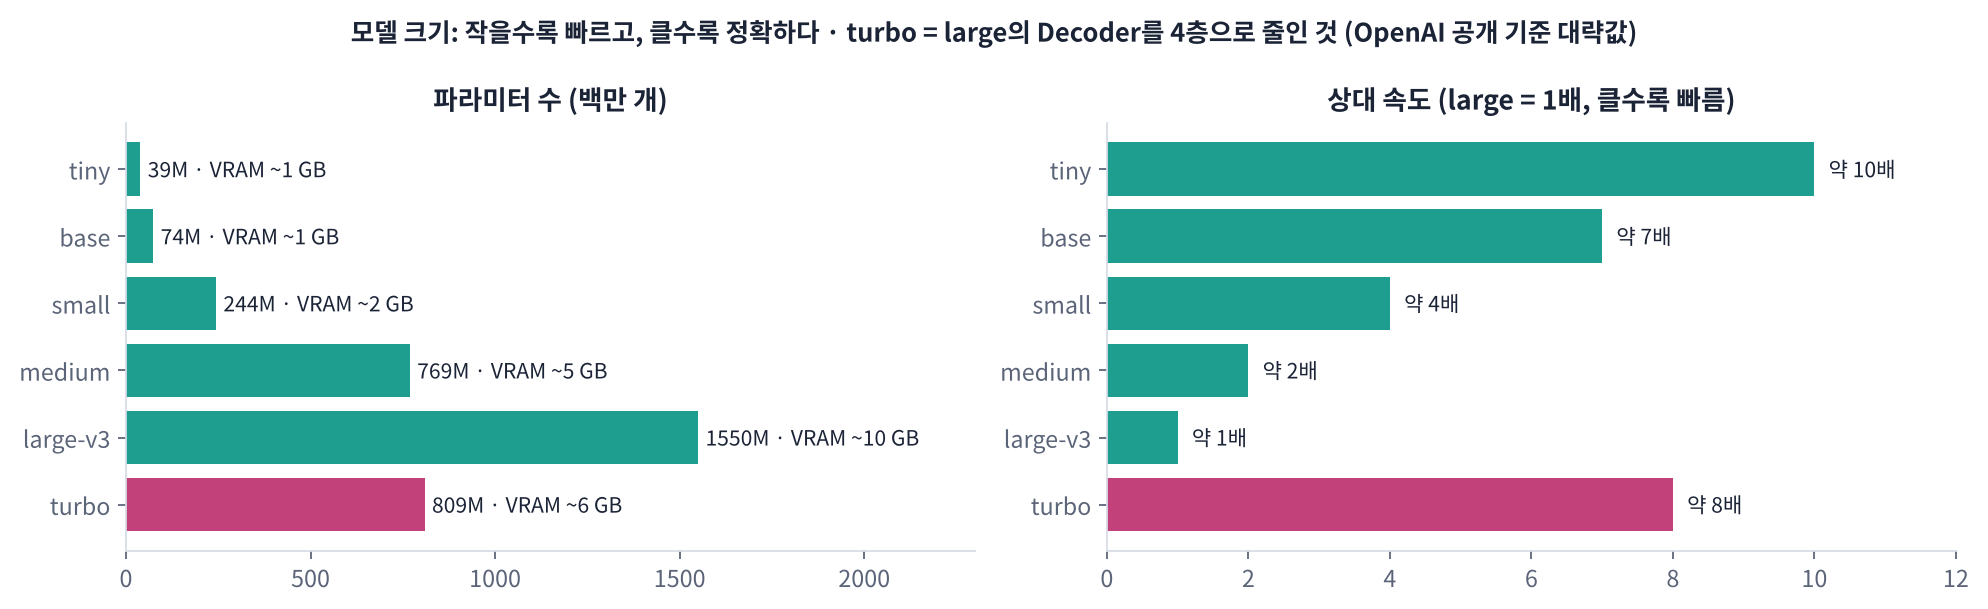

| 모델 | 파라미터 | 층 (Enc / Dec) | 필요한 GPU 메모리 | 상대 속도 | 이럴 때 |
|---|---|---|---|---|---|
| tiny | 39M | 4 / 4 | ~1 GB | ~10배 | 휴대폰 · 라즈베리파이, 영어 명령어 |
| base | 74M | 6 / 6 | ~1 GB | ~7배 | 가벼운 실시간 데모 |
| small | 244M | 12 / 12 | ~2 GB | ~4배 | **오늘의 기본.** 한국어 입문용 |
| medium | 769M | 24 / 24 | ~5 GB | ~2배 | 정확도가 더 필요할 때 |
| large-v3 | 1550M | 32 / 32 | ~10 GB | 1배 | 가장 정확, 번역도 가장 잘함 |
| **large-v3-turbo** | 809M | 32 / **4** | ~6 GB | ~8배 | large에 가까운 정확도 + 빠른 속도. **번역은 학습 안 함** |

(OpenAI 공개 기준 대략값. 실제 속도는 GPU · 음성 길이 · 구현에 따라 다릅니다.)

> 🍎 **비유: 자동차 배기량**. 경차(tiny)는 기름을 적게 먹고 빠르게 출발하지만 짐을 많이 못 싣고, 대형 트럭(large)은 무엇이든 싣지만 느립니다. **turbo**는 트럭의 큰 엔진(Encoder 32층)은 그대로 두고 무거운 짐칸(Decoder)을 4층으로 줄인 것입니다. Decoder는 토큰마다 반복해서 돌기 때문에(D6) 여기를 줄이면 속도가 크게 오릅니다.

### 2-1. 무엇으로 비교할까: CER과 RTF

| 지표 | 쉽게 말하면 | 좋은 값 |
|---|---|---|
| **CER** (Character Error Rate, 글자 오류율) | 정답 문장을 만들려면 **몇 %의 글자를 고쳐야 하나** | 작을수록 좋음. 0 = 완벽 |
| **RTF** (Real-Time Factor, 실시간 배율) | 1초짜리 음성을 받아 적는 데 **몇 초 걸리나** | 작을수록 빠름. **1보다 작으면 실시간보다 빠름** |

📐 **핵심 식 하나**

$$\text{RTF} = \frac{\text{받아 적는 데 걸린 시간}}{\text{음성 길이}}$$

**읽는 법**: 10초 음성을 2초 만에 받아 적으면 RTF = 0.2, "실시간보다 5배 빠르다". 실시간 자막이라면 RTF가 1보다 충분히 작아야 합니다.

CER은 한국어에 잘 맞는 지표입니다(띄어쓰기가 흔들려도 글자로 셈). 영어는 단어 단위 WER을 많이 씁니다. 자세한 계산과 정규화는 **D10**에서 합니다. 오늘은 `jiwer.cer()`을 그대로 씁니다.

In [ ]:
# ▶️ CER 맛보기: 정답과 받아쓰기 결과를 비교
def norm(s):
    # 비교 전에 문장 부호와 띄어쓰기를 지워 '글자'만 비교 (D10에서 자세히)
    return re.sub(r"[\s.,!?'\"·~-]", "", s).lower()

ref_txt = "안녕하세요 오늘은 음성 인식 모델 위스퍼를 자세히 알아보겠습니다"
for hyp in ["안녕하세요 오늘은 음성인식 모델 위스퍼를 자세히 알아보겠습니다.",   # 띄어쓰기 · 마침표만 다름
            "안녕하세요 오늘은 음성 인식 모델 위스퍼를 자세하게 알아보겠습니다",     # 한 단어가 다름
            "안녕하세요 오늘은 음성 인식 모델 Whisper를 알아봅니다"]:             # 여러 군데 다름
    print(f"CER {jiwer.cer(norm(ref_txt), norm(hyp)):6.1%} | {hyp}")

### 🧩 빈칸 실습 3: 크기별로 재 보기 (RTF · CER)
모델을 하나씩 불러 한국어 문장 2개를 받아 적고, 걸린 시간으로 **RTF**를 계산하세요. 모델마다 처음 한 번은 워밍업(첫 실행은 준비 시간이 섞여 느림)으로 버립니다.

> ⏱️ GPU에서 약 3~5분, CPU에서 약 3~6분 걸립니다(CPU는 turbo 제외). 기다리는 동안 [D7-4 모델 고르기](https://imguru-mooc.github.io/AI_Voice/day07/animation.html#sizes)를 해 보세요.

In [ ]:
# 🧩 빈칸 실습 3
CANDIDATES = ["openai/whisper-tiny", "openai/whisper-base", "openai/whisper-small"]
if DEVICE == "cuda":
    CANDIDATES.append("openai/whisper-large-v3-turbo")

test_keys = ["ko", "ko_terms"]
dur = sum(len(audio[k]) for k in test_keys) / SR                 # 음성 길이 합계 (초)
rows = []
for name in CANDIDATES:
    p = proc if name == MAIN else WhisperProcessor.from_pretrained(name)
    m = model if name == MAIN else WhisperForConditionalGeneration.from_pretrained(name, dtype=DTYPE).to(DEVICE).eval()
    transcribe(audio["ko"], m, p, language="ko")                  # 워밍업 (버림)
    if DEVICE == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    hyps = [transcribe(audio[k], m, p, language="ko") for k in test_keys]
    if DEVICE == "cuda": torch.cuda.synchronize()
    elapsed = time.time() - t0

    RTF = ____ / dur
    cer = jiwer.cer([norm(TEXTS[k][0]) for k in test_keys], [norm(h) for h in hyps])
    rows.append(dict(name=name.split("/")[-1], params=sum(x.numel() for x in m.parameters()) / 1e6, rtf=RTF, cer=cer, elapsed=elapsed, hyp=hyps[1]))
    print(f"{rows[-1]['name']:22s} {rows[-1]['params']:6.0f}M | RTF {RTF:.3f} | CER {cer:6.1%} | {hyps[1]}")
    if m is not model:
        del m; torch.cuda.empty_cache() if DEVICE == "cuda" else None

fig, ax = plt.subplots(figsize=(8, 4))
for r in rows:
    ax.scatter(r["rtf"], r["cer"] * 100, s=r["params"] / 3 + 30, alpha=0.7)
    ax.annotate(r["name"], (r["rtf"], r["cer"] * 100), textcoords="offset points", xytext=(6, 6))
ax.set_xlabel("RTF (lower = faster)"); ax.set_ylabel("CER % (lower = more accurate)")
ax.set_title("speed vs accuracy (bubble size = parameters)"); plt.tight_layout(); plt.show()
check(all(abs(r["rtf"] - r["elapsed"] / dur) < 1e-9 for r in rows) and len(rows) >= 3,
      hint="RTF = 걸린 시간 ÷ 음성 길이. 걸린 시간을 담은 변수는 elapsed 입니다.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
RTF = elapsed / dur
```

**해설**: `elapsed`는 문장 2개를 받아 적는 데 걸린 시간, `dur`은 두 음성 길이의 합입니다. 보통 **왼쪽 위(빠르지만 틀림) → 오른쪽 아래(느리지만 정확)** 로 점들이 늘어섭니다. turbo가 small보다 크면서도 빠르게 나오면 'Decoder를 줄인 효과'를 본 것입니다. gTTS 음성은 아주 깨끗해서 크기별 차이가 실제보다 작게 나옵니다. 잡음 · 사투리 · 전문 용어가 섞인 실제 음성에서는 차이가 훨씬 커집니다.

</details>

#### 결과 읽는 법

👣 **표를 이렇게 읽으세요**
1. **RTF가 1보다 작은가?** → 실시간 자막에 쓸 수 있는지의 기본 조건
2. **CER이 몇 %인가?** → 회의록이라면 5% 이하, 명령어 인식이라면 핵심 단어만 맞으면 됨
3. **'아이구루 · 라이브킷 · 파이프캣'** 같은 고유명사가 어떻게 나왔나? → 크기를 키워도 안 고쳐지면 **프롬프트**(Part 4-4)나 **Fine-tuning**(3주차)이 답

**❓ 생각해 보기**: 콜센터에서 동시에 100명의 통화를 실시간 자막으로 띄워야 합니다. GPU는 한 대뿐입니다. 어떤 모델부터 시험해 보겠습니까?

<details>
<summary>답 보기</summary>

**turbo 또는 small**부터 시험합니다. 100명이 동시에 쓰면 RTF가 0.01 수준(100배 빠름)은 되어야 버팁니다. large-v3는 정확하지만 느리고 메모리도 커서 동시 처리량이 부족합니다. 내일(D8) 배우는 **faster-whisper · 양자화 · 배치 처리**로 같은 모델을 몇 배 더 빠르게 만들 수도 있습니다.

</details>

## Part 3. 언어 감지와 번역

### 3-1. Whisper는 언어를 어떻게 알아낼까

> 💬 **쉽게 말하면**: 주문서 ②번 칸(언어)을 비워 두면, Decoder가 **SOT 다음에 올 토큰**을 예측합니다. 그 후보 중 99개 언어 토큰의 점수만 모아 확률로 바꾸면, 그게 곧 **언어 감지 결과**입니다. 따로 언어 감지 모델이 있는 게 아닙니다.

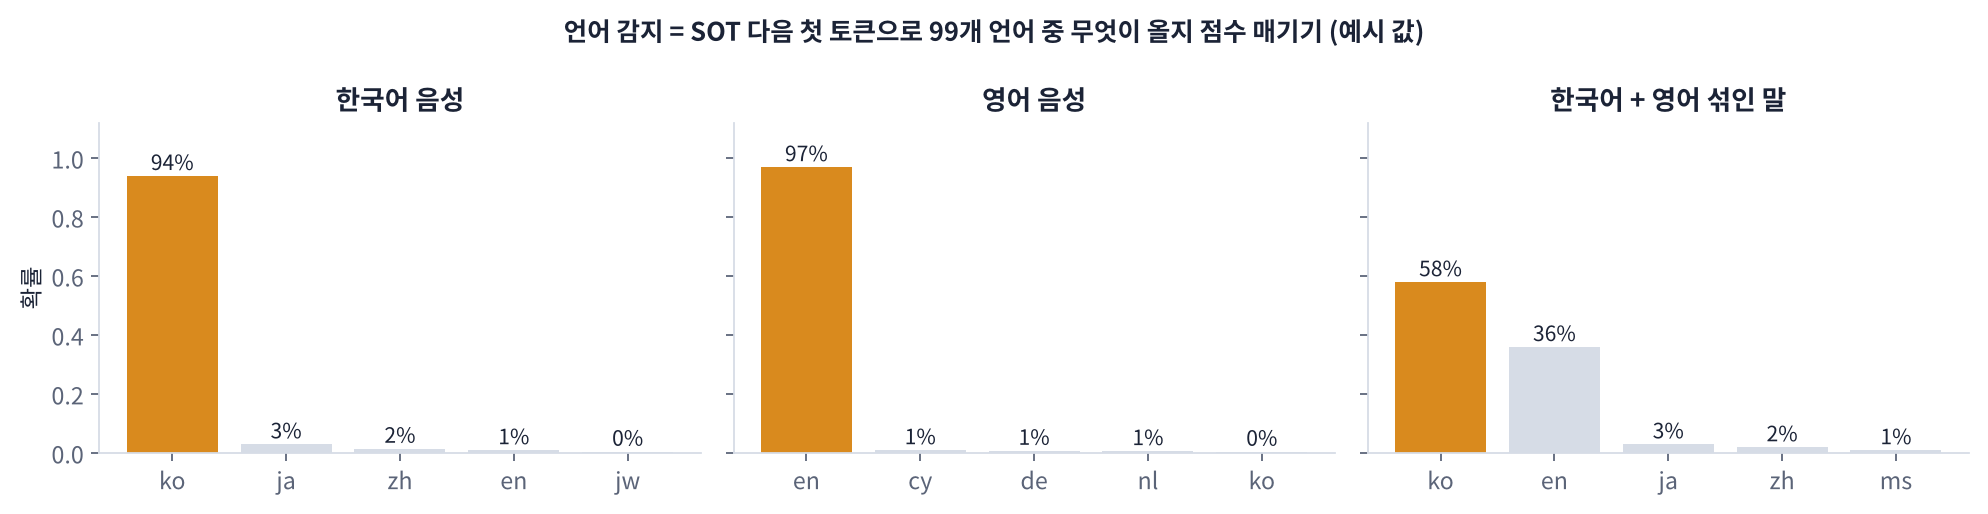

👣 **한 단계씩**
1. Encoder로 소리를 듣습니다 (Part 1과 같음).
2. Decoder에 `<|startoftranscript|>` **한 개만** 넣고, 다음 토큰 점수(어휘 약 5만 개)를 받습니다.
3. 그중 `<|ko|>`, `<|en|>`, `<|ja|>` … **언어 토큰 99개의 점수만** 골라냅니다.
4. softmax로 확률(합 = 100%)로 바꿉니다. 가장 큰 언어가 감지 결과입니다.

> 🍎 **비유**: 통역사에게 녹음을 들려주고 "첫 마디로 무슨 말을 하실 건가요?"라고 묻는 것과 같습니다. 대답 대신 "한국어로 시작하겠다 94%, 일본어 3%…"라는 망설임까지 보여 주는 셈입니다.

> 🎬 **애니메이션 D7-5:** [언어 감지](https://imguru-mooc.github.io/AI_Voice/day07/animation.html#langid) — 음성 종류를 골라 언어 확률 막대 보기, 짧은 음성 · 섞인 말에서 흔들리는 이유

### 🧩 빈칸 실습 4: 언어 토큰 점수만 골라내기
`logits[0, -1]`은 어휘 전체(약 5만 개)의 점수입니다. 그중 **언어 토큰 번호 목록**에 해당하는 칸만 꺼내세요.

In [ ]:
# 🧩 빈칸 실습 4
LANG2ID = model.generation_config.lang_to_id                       # {"<|en|>": 50259, "<|ko|>": 50264, ...}
LANG_NAMES = [k.strip("<|>") for k in LANG2ID]
LANG_IDS = list(LANG2ID.values())
print(f"언어 토큰 {len(LANG_IDS)}개, 예: {LANG_NAMES[:8]} ...")

def detect(y, m=model, p=proc):
    f = feats_of(y, p, m)
    sot = torch.tensor([[m.generation_config.decoder_start_token_id]], device=DEVICE)
    with torch.no_grad():
        logits = m(input_features=f, decoder_input_ids=sot).logits          # (1, 1, 어휘 수)
    lang_logits = logits[0, -1, ____].float()                              # 언어 토큰 점수만
    probs = lang_logits.softmax(-1)
    top = probs.topk(5)
    return [(LANG_NAMES[i], v.item()) for v, i in zip(top.values, top.indices)], f

fig, axs = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
results = {}
for ax, k in zip(axs, ["ko", "en", "ja", "mix"]):
    top5, f = detect(audio[k])
    results[k] = top5
    ax.bar([n for n, _ in top5], [v for _, v in top5], color=["tab:orange"] + ["lightgray"] * 4)
    ax.set_title(f"{k}: '{TEXTS[k][0][:14]}…'", fontsize=9); ax.set_ylim(0, 1.05)
    print(f"{k:4s} → " + ", ".join(f"{n} {v:.1%}" for n, v in top5))
plt.tight_layout(); plt.show()

builtin = model.generation_config.lang_to_id
inv = {v: k.strip("<|>") for k, v in builtin.items()}
with torch.no_grad():
    hf = inv[model.detect_language(feats_of(audio["ko"]))[0].item()]
print(f"\ntransformers 내장 detect_language(ko 음성) = {hf}")
check(results["ko"][0][0] == hf and abs(sum(v for _, v in results["ko"])) <= 1.0001,
      hint="언어 토큰 번호 목록 LANG_IDS를 넣습니다.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
lang_logits = logits[0, -1, LANG_IDS].float()
```

**해설**: 파이썬 리스트로 인덱싱하면 그 번호들의 칸만 골라 새 텐서(길이 99)가 됩니다. 어휘 전체가 아니라 **언어 토큰끼리만** softmax를 하므로 99개 확률의 합이 100%가 됩니다. transformers의 `detect_language()`도 속으로 같은 일을 합니다. 섞인 말(`mix`)에서는 한국어와 영어 확률이 나뉘는 것을 보세요.

</details>

#### 언어 감지가 틀리는 경우와 대처

| 상황 | 왜 틀리나 | 대처 |
|---|---|---|
| 1~2초짜리 짧은 말 ("네", "OK") | 단서가 너무 적음 | 서비스 언어가 정해져 있으면 **`language="ko"`로 고정** |
| 한국어 + 영어 섞인 말 | 두 언어 확률이 나뉨 | 주 언어로 고정. 영어 단어는 한국어 문장 속에서도 대체로 영어로 적힘 |
| 처음 몇 초가 음악 · 무음 | 앞부분만 보고 판단 | VAD로 말 구간부터 넣기 (Part 5) |
| 비슷한 언어 (한국어 ↔ 일본어, 스페인어 ↔ 포르투갈어) | 소리가 닮음 | 고정, 또는 확률이 낮으면 사람에게 확인 |

> 💡 **실무 원칙**: 서비스 언어를 알고 있다면 **언제나 `language=`를 지정**하세요. 감지 단계를 건너뛰니 조금 빠르고, 엉뚱한 언어로 받아 적는 사고(환각 유형 ④)를 막습니다.

### 3-2. 번역: 한국어 음성 → 영어 문장

> 💬 **쉽게 말하면**: 주문서 ③번 칸을 `<|translate|>`로 바꾸면 Whisper가 받아 적는 대신 **영어로 번역**합니다. 별도 번역 모델 없이 한 번에 됩니다. 단, **영어로만** 번역할 수 있습니다.

| 주의 | 이유 |
|---|---|
| 영어 → 한국어 번역은 안 됨 | 학습 데이터가 'X 언어 음성 → 영어 자막' 쌍뿐이었음 |
| **large-v3-turbo는 번역을 잘 못함** | turbo는 받아쓰기 데이터로만 다시 학습함. 번역은 small · medium · large-v3로 |
| 품질은 '받아쓰기 → 번역기(LLM)'보다 낮을 수 있음 | 5주차에서 STT → LLM 번역으로 더 좋은 결과를 만듭니다 |

### 🧩 빈칸 실습 5: 작업을 번역으로 바꾸기

In [ ]:
# 🧩 빈칸 실습 5
TASK = ____

for k in ["ko", "ko_terms"]:
    print(f"원문 ({k})    : {TEXTS[k][0]}")
    print(f"받아쓰기       : {transcribe(audio[k], language='ko', task='transcribe')}")
    print(f"번역 (→ 영어)  : {transcribe(audio[k], language='ko', task=TASK)}\n")
check(TASK == "translate", hint='작업 이름은 "translate" 입니다 (따옴표 포함).')

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
TASK = "translate"
```

**해설**: `task="translate"`를 주면 주문서 ③번 칸이 `<|translate|>`가 됩니다. 이때 `language="ko"`는 '**들어오는 음성이** 한국어'라는 뜻이지 출력 언어가 아닙니다. 출력은 항상 영어입니다. '아이구루' 같은 고유명사는 번역에서 더 쉽게 깨집니다. 받아쓰기에서 틀린 것은 번역에서도 틀립니다.

</details>

---
### 📝 2교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 2교시 탭](https://imguru-mooc.github.io/AI_Voice/day07/worksheet.html)** — 모델 크기와 메모리 · 속도, turbo = Decoder 4층, RTF 읽는 법, CER, 워밍업, 언어 감지 = 첫 토큰의 언어 확률, 언어 고정이 필요한 상황, translate는 영어로만, turbo는 번역 X
>
> 10문항을 풀고 **채점하기**를 누르세요. 결과 코드와 해설이 나옵니다. 채점 후에는 답이 잠깁니다. 제출은 4교시까지 모두 마친 뒤 한 번에 합니다.

## Part 4. 디코딩 옵션: 같은 모델, 다른 받아쓰기

> 💬 **쉽게 말하면**: 모델(귀와 손)은 그대로 두고 **'손이 다음 토큰을 고르는 방식'** 만 바꿔도 결과가 달라집니다. 오늘 볼 옵션은 다섯 가지입니다.

| 옵션 | 한 줄 설명 | generate() 인자 |
|---|---|---|
| greedy | 매번 1등 토큰만 고름 (기본값) | `num_beams=1` |
| beam search | 후보 문장 여러 개를 끝까지 들고 가서 가장 좋은 것 | `num_beams=5` |
| temperature | 1등이 아닌 토큰도 확률적으로 뽑음 | `do_sample=True, temperature=0.6` |
| 타임스탬프 | 문장마다 시작 · 끝 시각을 함께 적음 | `return_timestamps=True` |
| 프롬프트 | 앞에 힌트 문장을 깔아 용어 · 말투를 유도 | `prompt_ids=...` |

### 4-1. greedy vs beam search

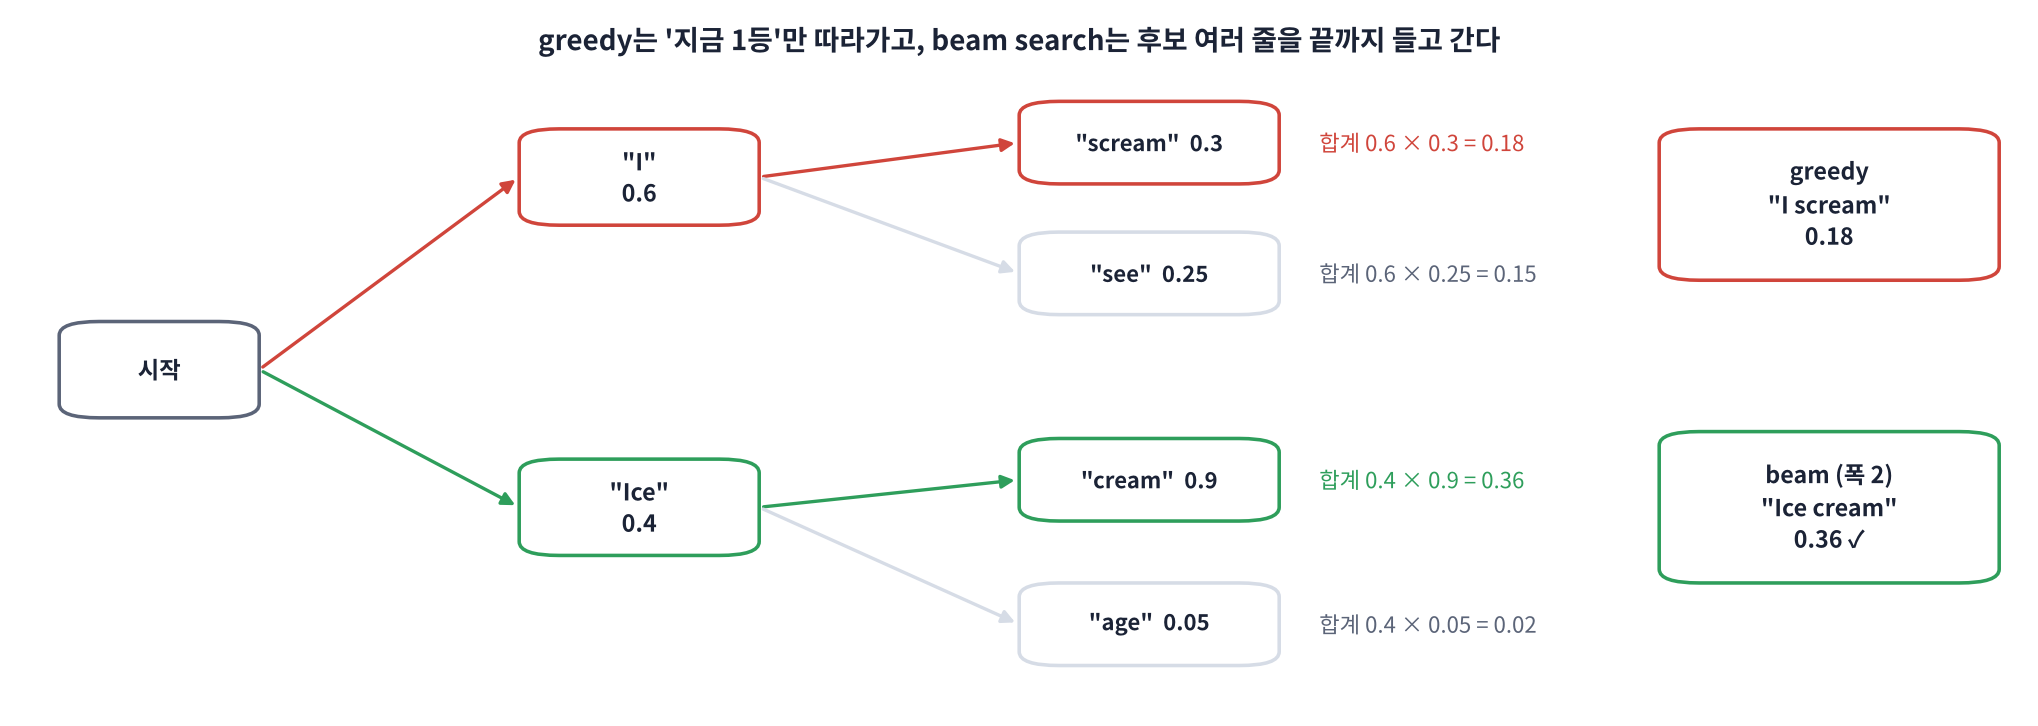

👣 **한 단계씩 (그림 읽기)**
1. 첫 단어 후보: "I" 0.6, "Ice" 0.4 → **greedy는 "I"를 고르고 끝까지 그 길만** 갑니다.
2. "I" 다음 후보 중 가장 좋은 "scream"도 0.3뿐 → 문장 점수 0.6 × 0.3 = **0.18**
3. **beam(폭 2)은 "Ice"도 버리지 않고** 들고 갑니다. "Ice" 다음 "cream"이 0.9 → 0.4 × 0.9 = **0.36**
4. 끝까지 가 보니 "Ice cream"이 더 좋은 문장 → beam이 이깁니다.

> 🍎 **비유: 길 찾기**. greedy는 갈림길마다 '지금 가장 넓은 길'로만 가는 운전자, beam search는 **가능성 있는 길 5개에 동시에 정찰병을 보내** 끝까지 가 본 뒤 가장 좋은 길을 고르는 운전자입니다. 정찰병이 많을수록 좋은 길을 찾지만 **기름(계산)이 그만큼 더 듭니다.**

Whisper 원본 프로그램(`whisper` CLI)의 기본값은 **beam 5**, transformers `generate()`의 기본값은 **greedy**입니다. 같은 모델인데 결과가 조금 다르다면 이 차이를 먼저 의심하세요.

> 🎬 **애니메이션 D7-6:** [빔 서치](https://imguru-mooc.github.io/AI_Voice/day07/animation.html#beam) — 빔 폭을 1~4로 바꿔 가며 후보 문장이 살아남고 떨어지는 과정 보기

In [ ]:
# 어려운 음성 만들기: 조금 빠르게(1.25배) + 잡음 (SNR 5 dB)
def add_noise(y, snr_db, seed=0):
    rng = np.random.default_rng(seed)
    n = rng.standard_normal(len(y)).astype(np.float32)
    n *= np.sqrt(np.mean(y ** 2) / (10 ** (snr_db / 10)) / np.mean(n ** 2))
    return (y + n).astype(np.float32)

hard = add_noise(librosa.effects.time_stretch(audio["ko_terms"], rate=1.25), snr_db=5)
print(f"원래 {len(audio['ko_terms']) / SR:.1f}초 → 빠르게 + 잡음 {len(hard) / SR:.1f}초")
display(Audio(hard, rate=SR))

### 🧩 빈칸 실습 6: 빔 폭 정하기
Whisper 원본 프로그램과 같은 **빔 폭 5**로 받아 적고 greedy와 비교하세요.

In [ ]:
# 🧩 빈칸 실습 6
NUM_BEAMS = ____

ref = norm(TEXTS["ko_terms"][0])
for label, kw in [("greedy (num_beams=1)", dict(num_beams=1)), (f"beam (num_beams={NUM_BEAMS})", dict(num_beams=NUM_BEAMS))]:
    t0 = time.time()
    hyp = transcribe(hard, language="ko", **kw)
    print(f"{label:22s} | {time.time() - t0:5.2f}초 | CER {jiwer.cer(ref, norm(hyp)):6.1%} | {hyp}")
check(NUM_BEAMS == 5, hint="Whisper 원본의 기본 빔 폭은 5입니다.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
NUM_BEAMS = 5
```

**해설**: beam은 후보 5줄을 동시에 계산하므로 **시간은 늘어나고**, CER은 같거나 조금 좋아지는 경우가 많습니다. 깨끗한 음성에서는 차이가 거의 없을 수 있습니다. 1등이 확실하면 greedy와 beam이 같은 답을 내기 때문입니다. **애매한 음성일수록** beam의 덕을 봅니다.

</details>

### 4-2. temperature: 일부러 '모험'하기

> 💬 **쉽게 말하면**: 보통은 매번 1등 토큰을 고릅니다(temperature = 0). temperature를 올리면 2등, 3등 토큰도 **주사위를 굴려** 뽑습니다. 결과가 실행할 때마다 달라집니다.

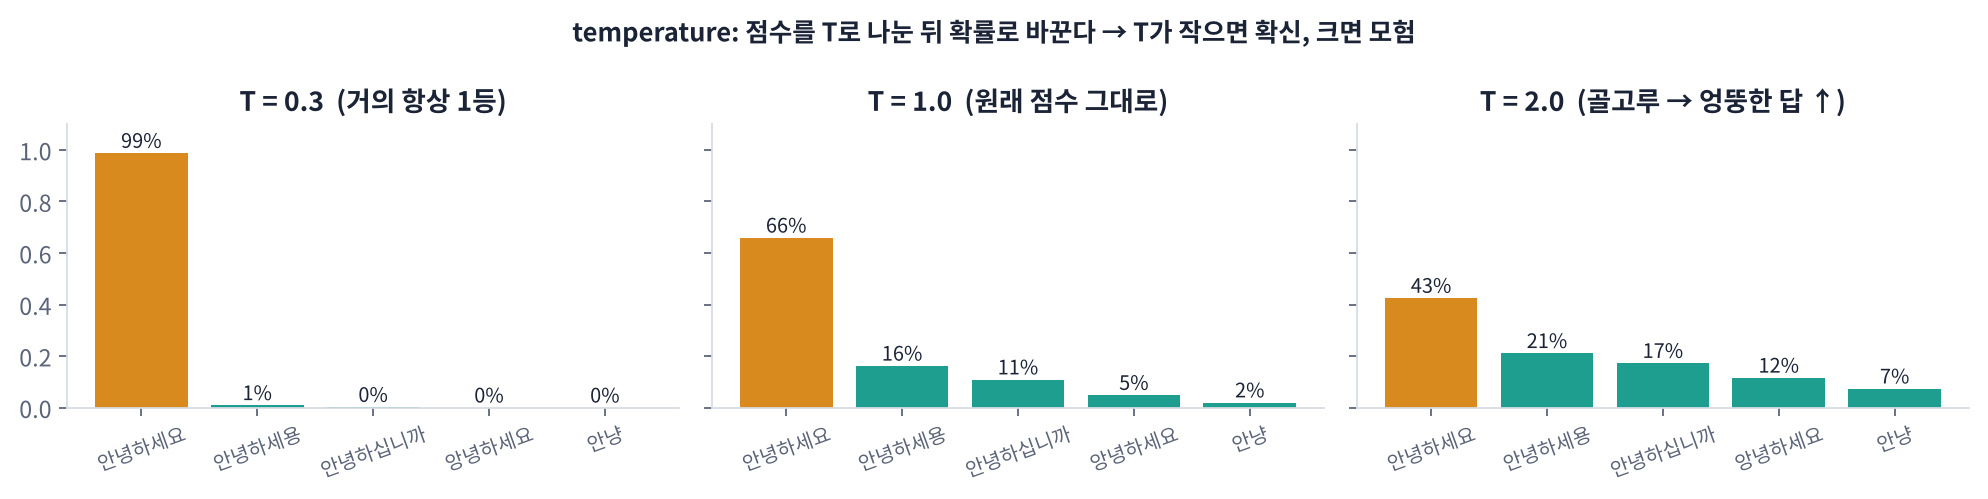

📐 **핵심 식 하나**

$$p_k = \text{softmax}\left(\frac{z_k}{T}\right)$$

**읽는 법**: 모델 점수 $z$를 $T$로 **나눈 뒤** 확률로 바꿉니다. $T$가 작으면(0.3) 점수 차가 커져서 1등이 거의 다 가져가고, 크면(2.0) 점수 차가 줄어 확률이 골고루 퍼집니다. $T = 0$은 '항상 1등' = greedy입니다.

**그럼 왜 일부러 모험을 할까?** 받아쓰기에서 다양성이 필요한 건 아닙니다. 쓰임은 하나, **'막혔을 때 탈출'** 입니다. greedy가 같은 말을 반복하는 고리에 빠지면, 온도를 조금 올려 다른 길로 빠져나오게 합니다. 이것이 4교시의 **temperature fallback**입니다.

> 🎬 **애니메이션 D7-7:** [temperature와 fallback](https://imguru-mooc.github.io/AI_Voice/day07/animation.html#temp) — T 슬라이더로 확률 막대가 퍼지는 모습, 주사위 굴리기, fallback 사다리

In [ ]:
# ▶️ 확인: 같은 어려운 음성을 temperature별로 3번씩 받아 적기
torch.manual_seed(0)
for T in [0.0, 0.6, 1.2]:
    kw = dict(num_beams=1) if T == 0 else dict(do_sample=True, temperature=T)
    outs = [transcribe(hard, language="ko", **kw) for _ in range(3)]
    print(f"T = {T} → 서로 다른 결과 {len(set(outs))}개")
    for o in outs:
        print(f"    CER {jiwer.cer(ref, norm(o)):6.1%} | {o}")

**결과 읽기**: T = 0은 3번 모두 같은 문장(서로 다른 결과 1개), T가 커질수록 문장이 흔들리고 CER도 대체로 나빠집니다. 그래서 받아쓰기의 **기본은 T = 0**, 온도는 '비상구'로만 씁니다.

### 4-3. 타임스탬프: 언제 말했는지 함께 적기

> 💬 **쉽게 말하면**: 주문서에서 `<|notimestamps|>`를 빼면, Whisper가 문장 앞뒤에 `<|1.24|>` 같은 **시각 토큰**을 끼워 적습니다. 자막(SRT) 만들기의 출발점입니다.

👣 **한 단계씩**
1. 시각 토큰은 `<|0.00|>`, `<|0.02|>`, …, `<|30.00|>`까지 **0.02초 간격 1501개**가 어휘에 들어 있습니다 (Encoder 한 칸 = 20 ms와 같은 간격).
2. Decoder는 "시작 시각 → 문장 → 끝 시각" 순서로 적습니다: `<|0.00|> 안녕하세요. <|1.80|>`
3. `decode(..., output_offsets=True)`가 이 토큰들을 (시작, 끝, 문장) 묶음으로 정리해 줍니다.

⚠️ 이 시각은 **문장(구간) 단위**이고 ±0.5초쯤 틀릴 수 있습니다. **단어 단위**의 정확한 시각은 D9(WhisperX)에서 D6의 CTC 정렬로 만듭니다.

> 🎬 **애니메이션 D7-8:** [타임스탬프와 프롬프트](https://imguru-mooc.github.io/AI_Voice/day07/animation.html#stamp) — 시각 토큰이 끼워진 출력을 타임라인으로, 프롬프트 켜고 끄기

In [ ]:
# ▶️ 확인: 문장 3개를 0.7초 쉬며 이어 붙인 음성으로 타임스탬프 받기
gap = np.zeros(int(0.7 * SR), dtype=np.float32)
story = np.concatenate([audio["ko"], gap, audio["ko_terms"], gap, audio["mix"]])
with torch.no_grad():
    ids = model.generate(feats_of(story), language="ko", return_timestamps=True)
print("시각 토큰이 섞인 원래 출력:")
print("   ", tok.decode(ids[0], skip_special_tokens=False, decode_with_timestamps=True)[:300], "...\n")
segs = tok.decode(ids[0], output_offsets=True, skip_special_tokens=True)["offsets"]
for s in segs:
    a, b = s["timestamp"]
    print(f"[{a:5.2f} → {(b if b is not None else float('nan')):5.2f}] {s['text'].strip()}")

fig, ax = plt.subplots(figsize=(13, 2.6))
ax.plot(np.arange(len(story)) / SR, story, lw=0.4, color="tab:cyan")
for i, s in enumerate(segs):
    a, b = s["timestamp"]; b = b if b is not None else len(story) / SR
    ax.axvspan(a, b, alpha=0.18, color=["tab:orange", "tab:green", "tab:purple"][i % 3])
    ax.text((a + b) / 2, 0.9 * np.abs(story).max(), f"seg {i + 1}", ha="center")
ax.set_xlabel("time (s)"); ax.set_title("Whisper segment timestamps"); plt.tight_layout(); plt.show()

### 4-4. 프롬프트: 모르는 단어에 힌트 주기

> 💬 **쉽게 말하면**: 받아 적기 **전에** 'Decoder가 이미 이런 문장을 썼다'고 믿게 만드는 힌트 문장을 앞에 깔아 둡니다. 그러면 그 안의 **단어 · 표기 · 말투**를 따라 하려는 경향이 생깁니다.

👣 **한 단계씩**
1. 힌트 문장을 토큰으로 바꾸고 맨 앞에 `<|startofprev|>`(= '이전 문장') 표시를 붙입니다.
2. 그 뒤에 원래 주문서(`<|startoftranscript|> <|ko|> …`)가 이어집니다.
3. Decoder는 힌트를 '바로 앞 30초에 받아 쓴 내용'으로 여기고, 비슷한 단어를 고르기 쉬워집니다.

> 🍎 **비유**: 속기사에게 "오늘 회의엔 '아이구루', '라이브킷' 같은 말이 나와요"라고 **용어 쪽지**를 건네는 것과 같습니다. 쪽지에 없는 내용을 만들어 내라는 뜻은 아닙니다.

| 쓰면 좋은 경우 | 조심할 점 |
|---|---|
| 회사명 · 제품명 · 사람 이름 · 전문 용어 | 너무 길면 안 됨 (최대 약 224토큰) |
| 표기 통일 (예: "LiveKit"을 영어로 쓰게) | 소리가 거의 없는 구간에서는 **힌트를 그대로 베껴 쓰는 환각** (유형 ③) |
| 문장 부호 · 말투 맞추기 (마침표 넣기 등) | '지시문'처럼 쓰면 안 됨 ("다음을 받아 적어라" ✗). 받아 쓴 문장처럼 써야 함 |

### 🧩 빈칸 실습 7: 용어 쪽지를 프롬프트로 넣기
`proc.get_prompt_ids()`에 힌트 문장 변수를 넣어 토큰으로 바꾸세요.

In [ ]:
# 🧩 빈칸 실습 7
PROMPT = "아이구루 교육센터, 라이브킷, 파이프캣, 음성 에이전트."
prompt_ids = proc.get_prompt_ids(____, return_tensors="pt").to(DEVICE)
print("프롬프트 토큰:", tok.convert_ids_to_tokens(prompt_ids[:6].tolist()), "...")

def strip_prompt(text):
    # transformers 버전에 따라 출력 앞에 프롬프트가 붙어 나오는 경우가 있어 떼어 냄
    return text[len(PROMPT):].strip() if text.startswith(PROMPT) else text

ref = norm(TEXTS["ko_terms"][0])
for label, y in [("깨끗한 음성", audio["ko_terms"]), ("어려운 음성", hard)]:
    no_p = transcribe(y, language="ko")
    with_p = strip_prompt(transcribe(y, language="ko", prompt_ids=prompt_ids))
    print(f"\n[{label}]")
    print(f"  프롬프트 없음 | CER {jiwer.cer(ref, norm(no_p)):6.1%} | {no_p}")
    print(f"  프롬프트 있음 | CER {jiwer.cer(ref, norm(with_p)):6.1%} | {with_p}")
check(prompt_ids[0].item() == tok.convert_tokens_to_ids("<|startofprev|>") and len(prompt_ids) > 3,
      hint="위에서 만든 힌트 문장 변수 PROMPT를 넣습니다.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
prompt_ids = proc.get_prompt_ids(PROMPT, return_tensors="pt").to(DEVICE)
```

**해설**: 결과 토큰의 맨 앞이 `<|startofprev|>`인 것을 확인하세요. '아이구루 · 라이브킷 · 파이프캣'이 프롬프트 표기대로 나오기 쉬워집니다. 다만 **항상 고쳐지는 것은 아닙니다.** 소리가 아주 다르면 힌트를 무시하고, 반대로 소리가 없으면 힌트를 베껴 씁니다. 회사 용어가 많다면 3주차의 **Fine-tuning**이 근본 해결책입니다.

</details>

---
### 📝 3교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 3교시 탭](https://imguru-mooc.github.io/AI_Voice/day07/worksheet.html)** — greedy vs beam search, 빔 폭과 계산량, 원본 CLI(beam 5)와 generate()(greedy) 기본값 차이, temperature의 뜻과 쓰임, 시각 토큰 0.02초 간격, 구간 vs 단어 타임스탬프, 프롬프트(`<|startofprev|>`)의 효과와 부작용
>
> 10문항을 풀고 **채점하기**를 누르세요. 결과 코드와 해설이 나옵니다. 채점 후에는 답이 잠깁니다. 제출은 4교시까지 모두 마친 뒤 한 번에 합니다.

## Part 5. 환각(hallucination): 들리지 않은 말을 지어낸다

> 💬 **쉽게 말하면**: Whisper의 손(Decoder)은 사실상 **'자막을 많이 읽은 언어 모델'** 입니다. 소리 단서가 약하면 귀(Encoder) 대신 **자기가 자주 본 문장**에 기대서 글을 지어냅니다. 이것이 환각입니다.

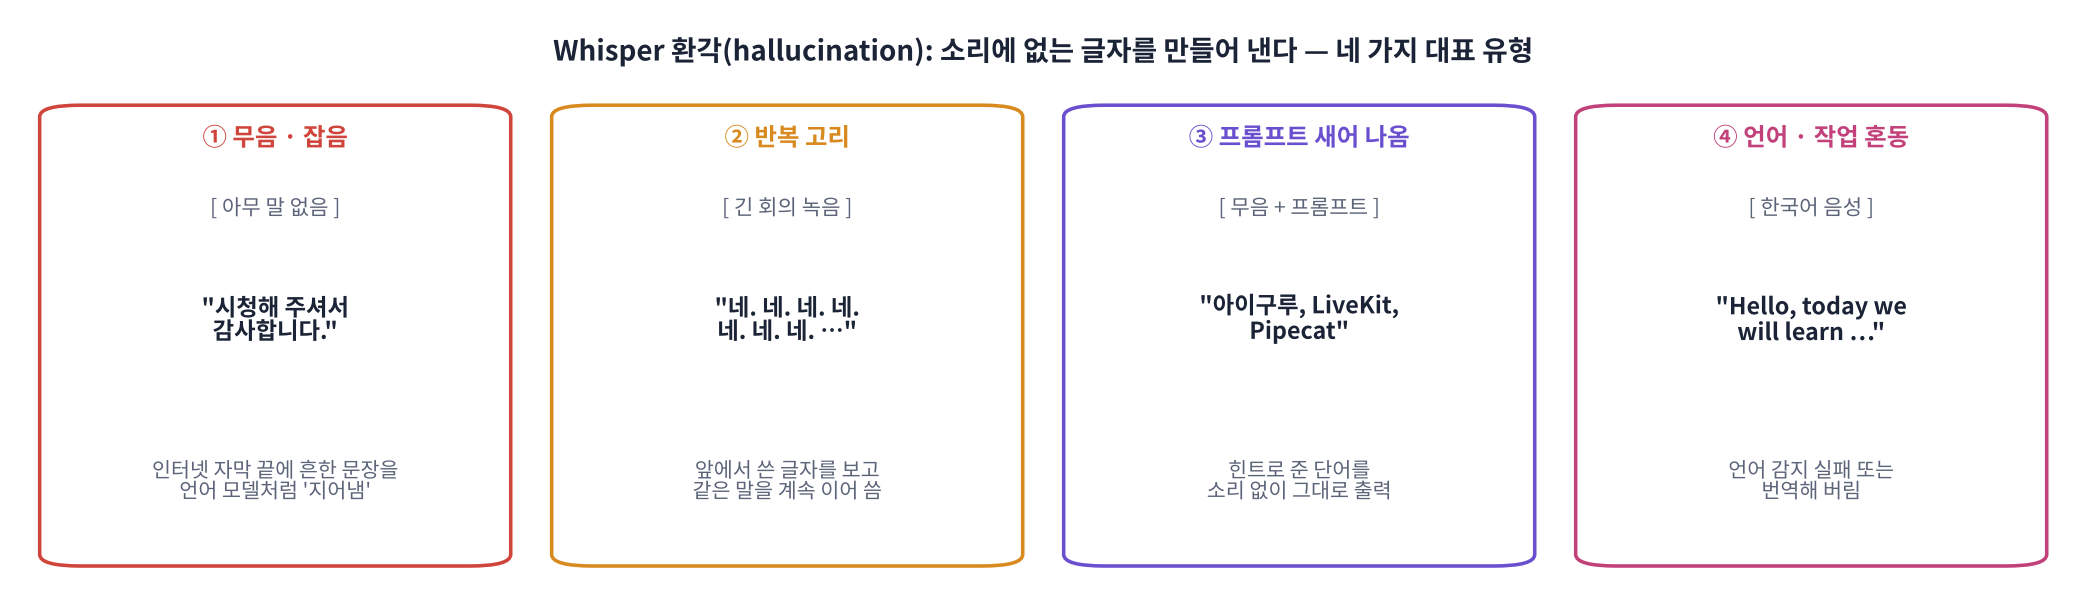

**왜 하필 "시청해 주셔서 감사합니다"일까?** Whisper는 인터넷 영상의 자막으로 학습했습니다. 영상 끝의 **박수 · 음악 · 무음 구간**에는 자막으로 "시청해 주셔서 감사합니다", "구독과 좋아요 부탁드립니다" 같은 문장이 자주 달려 있었습니다. 그래서 모델은 **'소리가 별로 없음 → 이 문장'** 이라는 연결을 함께 배웠습니다.

> 🍎 **비유**: 시험에서 들리지 않는 문제를 만난 학생이 빈칸으로 두지 않고 **"평소에 자주 나오던 답"을 적어 내는** 것과 같습니다. 빈칸이면 0점이지만 찍으면 맞을 수도 있었으니까요. 모델도 학습할 때 '빈칸 제출'로 상을 받은 적이 거의 없습니다.

| 유형 | 언제 | 무엇이 위험한가 | 오늘의 대응 |
|---|---|---|---|
| ① 무음 · 잡음 → 상투 문장 | 통화 대기, 회의 쉬는 시간, 음악 | 없던 말이 회의록에 남음 | **무음 확률**(5-2), **VAD**(5-5) |
| ② 반복 고리 | 긴 녹음, 앞 문장을 계속 참고할 때 | 같은 문장이 수십 번 | **압축률**(5-3), fallback · 이전 문장 참고 끄기(5-4) |
| ③ 프롬프트 베끼기 | 프롬프트 + 무음 | 힌트 단어가 그대로 출력 | VAD로 무음 제거, 짧은 프롬프트 |
| ④ 언어 · 작업 혼동 | 짧은 말, 섞인 말 | 번역되어 나오거나 다른 언어 | `language=` 고정 (Part 3) |

> 🎬 **애니메이션 D7-9:** [환각 실험실](https://imguru-mooc.github.io/AI_Voice/day07/animation.html#halluc) — 무음 · 반복 · 프롬프트 상황을 고르고 안전장치를 하나씩 켜며 결과가 깨끗해지는 과정

### 5-1. 실험 1: 아무 말도 없는 소리를 넣어 보기

10초짜리 '거의 무음'(아주 작은 잡음)과 '웅웅거리는 소리'(낮은 음 + 잡음)를 만들어 받아 적게 합니다.

> ⚠️ 결과는 **모델 크기 · 버전 · 실행마다 다릅니다.** 상투 문장이 나올 수도, 빈 문자열이 나올 수도, 아무 단어나 나올 수도 있습니다. 어떤 결과든 "소리에 없는 글자가 나왔는가"만 보세요.

In [ ]:
rng = np.random.default_rng(1)
t10 = np.arange(10 * SR) / SR
quiet = (0.002 * rng.standard_normal(10 * SR)).astype(np.float32)                                   # 거의 무음
hum = (0.05 * np.sin(2 * np.pi * 110 * t10) + 0.02 * rng.standard_normal(10 * SR)).astype(np.float32)  # 웅웅거림
nonspeech = {"거의 무음": quiet, "웅웅거림": hum}

for name, y in nonspeech.items():
    outs = {lang: transcribe(y, language=lang) for lang in ["ko", "en"]}
    print(f"[{name}] ko 고정 → {outs['ko']!r}")
    print(f"{'':{len(name) + 2}s} en 고정 → {outs['en']!r}")

### 5-2. 무음 확률: '쓸 게 있었나?'를 모델에게 묻기

> 💬 **쉽게 말하면**: Whisper는 학습할 때 말이 없는 구간에 **`<|nospeech|>`** 라는 특수 토큰을 쓰도록 배웠습니다. 그래서 SOT 다음에 이 토큰이 올 확률을 보면 **'이 30초에 말이 있었는가'** 를 물어볼 수 있습니다.

👣 **한 단계씩**
1. 언어 감지(Part 3)와 똑같이 SOT 하나만 넣고 다음 토큰 확률을 구합니다.
2. 이번에는 언어 토큰 대신 **`<|nospeech|>` 한 칸의 확률**만 봅니다. (예전 모델에서는 이름이 `<|nocaptions|>`)
3. 이 확률이 **0.6보다 크면** '무음 구간일 가능성이 크다'고 봅니다(Whisper 기본 기준).

### 🧩 빈칸 실습 8: 무음 확률 꺼내기
SOT 다음 토큰 확률 `probs`(어휘 크기)에서 **무음 토큰 번호** 칸의 값을 꺼내세요.

In [ ]:
# 🧩 빈칸 실습 8
cands = [tok.convert_tokens_to_ids(t) for t in ("<|nospeech|>", "<|nocaptions|>")]
NOSPEECH = next(i for i in cands if i is not None and i != tok.unk_token_id)   # 모델 버전에 맞는 무음 토큰 번호
print(f"무음 토큰: {tok.convert_ids_to_tokens(NOSPEECH)} (번호 {NOSPEECH}) | notimestamps 바로 앞 = {model.generation_config.no_timestamps_token_id - 1}")

def no_speech_prob(y, m=model, p=proc):
    f = feats_of(y, p, m)
    sot = torch.tensor([[m.generation_config.decoder_start_token_id]], device=DEVICE)
    with torch.no_grad():
        probs = m(input_features=f, decoder_input_ids=sot).logits[0, -1].float().softmax(-1)
    return probs[____].item()

rows = {"말 (ko)": audio["ko"], "말 (어려운 음성)": hard, **nonspeech}
for name, y in rows.items():
    ns = no_speech_prob(y)
    print(f"{name:14s} | P(무음) = {ns:6.1%} {'→ 무음으로 판단 (0.6 초과)' if ns > 0.6 else ''}")
vals = [no_speech_prob(y) for y in rows.values()]
check(all(0 <= v <= 1 for v in vals) and NOSPEECH == model.generation_config.no_timestamps_token_id - 1,
      hint="무음 토큰 번호를 담은 변수 NOSPEECH를 넣습니다.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
return probs[NOSPEECH].item()
```

**해설**: 보통 말이 있는 음성은 P(무음)이 몇 % 이하, 거의 무음은 훨씬 높게 나옵니다. 하지만 **이 값 하나만 믿으면 안 됩니다.** 작은 목소리를 무음으로 보거나, 웅웅거림을 말로 볼 수 있습니다. 그래서 Whisper는 '무음 확률이 높다' **그리고** '받아 쓴 문장에 자신이 없다'(평균 확신 낮음)일 때만 그 구간을 버립니다(5-4).

</details>

### 5-3. 압축률: 같은 말 반복을 숫자로 잡기

> 💬 **쉽게 말하면**: 같은 말이 반복된 글은 **zip으로 압축하면 아주 작아집니다.** 원래 크기 ÷ 압축한 크기(압축률)가 크면 '반복 고리에 빠졌다'고 의심합니다.

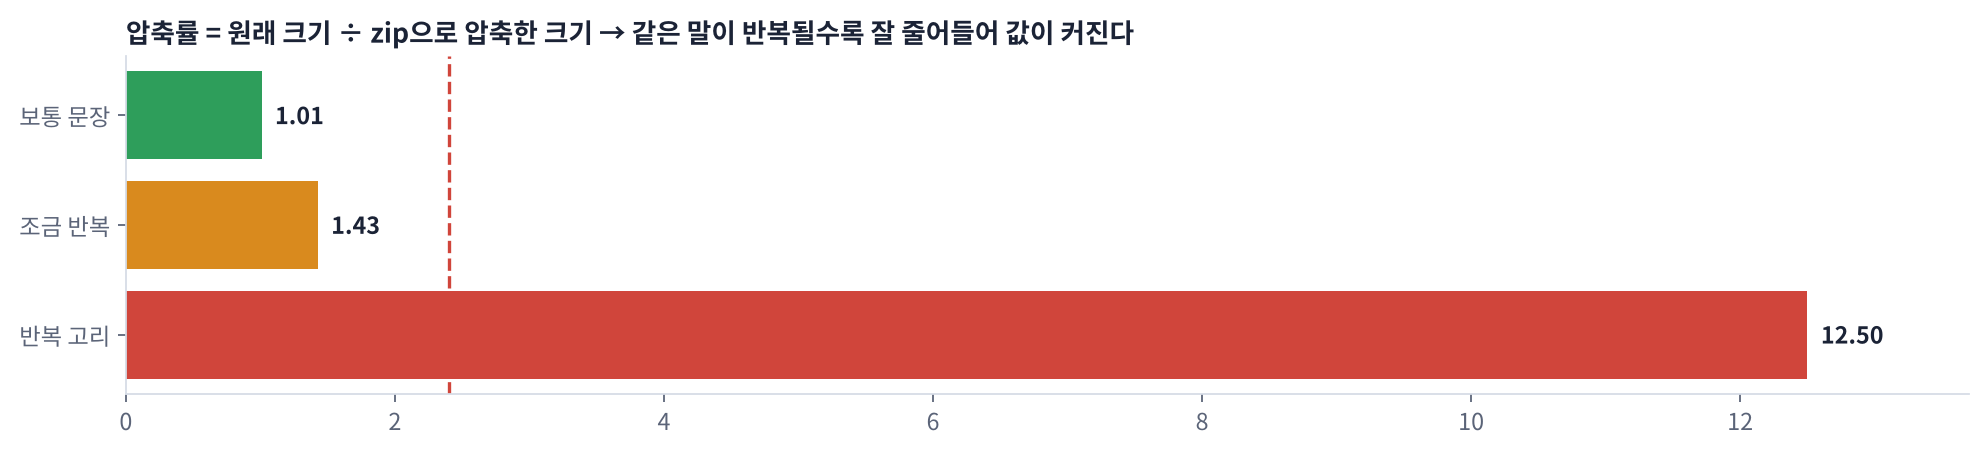

📐 **핵심 식 하나**

$$\text{압축률} = \frac{\text{원래 글의 바이트 수}}{\text{zlib로 압축한 바이트 수}}$$

**읽는 법**: 보통 문장은 1 근처, 반복이 심하면 5 이상까지 올라갑니다. Whisper 원본은 **2.4를 넘으면 '수상하다'** 고 봅니다.

> 🍎 **비유**: "네 네 네 네 …"를 40번 쓴 쪽지는 **"네 × 40"** 한 줄로 줄일 수 있습니다. 많이 줄어든다는 것은 내용이 반복된다는 뜻입니다. zip 압축이 바로 이런 '× 40'을 찾아냅니다.

### 🧩 빈칸 실습 9: 압축률 함수
`zlib` 모듈에서 바이트를 **압축하는** 함수 이름을 넣으세요.

In [ ]:
# 🧩 빈칸 실습 9
def compression_ratio(text):
    b = text.encode("utf-8")
    return len(b) / len(zlib.____(b))

samples = {
    "보통 문장": TEXTS["ko"][0],
    "조금 반복": "네 맞습니다. 네 맞습니다. 그렇게 진행하면 됩니다. 네 맞습니다.",
    "반복 고리": "네. " * 40,
    "영어 반복": "Thank you. " * 30,
}
for name, s in samples.items():
    r = compression_ratio(s)
    print(f"{name:7s} | 압축률 {r:5.2f} {'⚠️ 2.4 초과 → 반복 의심' if r > 2.4 else ''} | {s[:40]}...")
check(compression_ratio("네. " * 40) > 2.4 > compression_ratio(TEXTS["ko"][0]), hint="zlib.compress 입니다.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
return len(b) / len(zlib.compress(b))
```

**해설**: zlib는 파이썬에 기본으로 들어 있는 압축 도구(zip과 같은 방식)입니다. 반복 고리는 압축률이 10 이상까지도 올라갑니다. 한국어 보통 문장은 1 근처로 낮게 나옵니다. 한글은 한 글자가 3바이트라서 원래 크기가 큰데, 반복이 없으면 압축이 잘 안 되기 때문입니다.

</details>

### 5-4. Whisper의 기본 안전장치 켜기 (긴 음성)

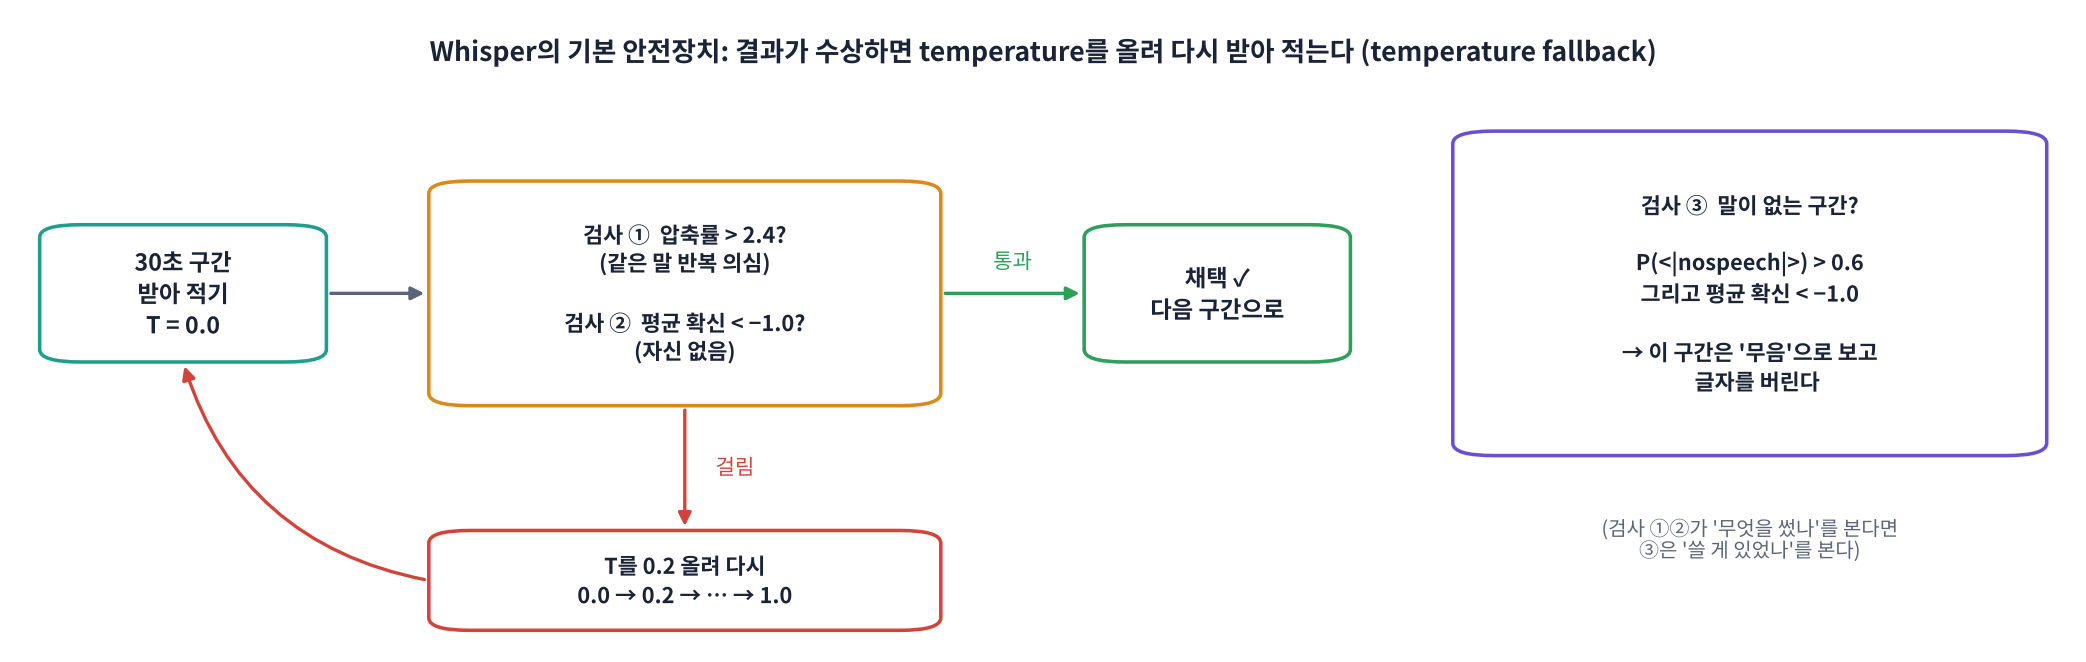

> 💬 **쉽게 말하면**: 긴 음성을 30초씩 받아 적을 때, 구간마다 **세 가지 검사**를 합니다. 걸리면 temperature를 올려 다시 받아 적거나(①②), 그 구간을 무음으로 보고 버립니다(③).

| 검사 | 무엇을 보나 | Whisper 원본 기준 | transformers 인자 |
|---|---|---|---|
| ① 압축률 | 같은 말 반복 | 2.4 초과면 다시 | `compression_ratio_threshold=1.35` ※ |
| ② 평균 확신 | 토큰마다 확률의 log 평균. **−1.0 ≈ 토큰 하나당 평균 37%** | −1.0 미만이면 다시 | `logprob_threshold=-1.0` |
| ③ 무음 | P(`<|nospeech|>`) > 0.6 **그리고** ②도 낮음 | 그 구간 버림 | `no_speech_threshold=0.6` |
| 다시 받아 적기 | T = 0.0 → 0.2 → … → 1.0 | 6번까지 | `temperature=(0.0, 0.2, 0.4, 0.6, 0.8, 1.0)` |
| 이전 문장 참고 | 앞 구간의 결과를 프롬프트로 이어 줌 | 기본 켜짐 | `condition_on_prev_tokens=False` 권장 ※※ |

※ transformers는 **글자가 아니라 토큰 번호**를 압축해서 값의 크기가 다릅니다. 그래서 같은 역할의 기준이 **1.35**입니다(transformers 문서 권장값).

※※ 앞 구간 결과를 참고하면 문맥이 이어져 좋지만, **앞 구간에서 반복 고리에 빠지면 다음 구간도 따라 빠집니다.** 환각이 걱정되면 끄는 것이 안전합니다.

아래에서는 문장들 사이에 **10초 무음**을 끼운 약 40초짜리 음성을 만들어, 안전장치 없이/있게 받아 적어 비교합니다.

In [ ]:
# 긴 음성 만들기: 문장 4개 + 중간에 10초 거의 무음 (총 30초 초과 → long-form)
gap = np.zeros(int(0.6 * SR), dtype=np.float32)
long_y = np.concatenate([audio["ko"], gap, audio["ko_terms"], quiet, audio["mix"], gap, audio["ko"], gap, audio["ko_terms"]])
print(f"긴 음성: {len(long_y) / SR:.1f}초")

def transcribe_long(y, **kw):
    inp = proc(y, sampling_rate=SR, return_tensors="pt", truncation=False, padding="longest", return_attention_mask=True)
    inp = {k: v.to(DEVICE) for k, v in inp.items()}
    inp["input_features"] = inp["input_features"].to(model.dtype)
    with torch.no_grad():
        out = model.generate(**inp, language="ko", return_timestamps=True, **kw)
    return tok.batch_decode(out, skip_special_tokens=True)[0].strip()

SAFE = dict(condition_on_prev_tokens=False, temperature=(0.0, 0.2, 0.4, 0.6, 0.8, 1.0),
            compression_ratio_threshold=1.35, logprob_threshold=-1.0, no_speech_threshold=0.6)

t0 = time.time(); plain = transcribe_long(long_y); t_plain = time.time() - t0
t0 = time.time(); safe = transcribe_long(long_y, **SAFE); t_safe = time.time() - t0
ref_long = " ".join(TEXTS[k][0] for k in ["ko", "ko_terms", "mix", "ko", "ko_terms"])
print(f"\n[안전장치 없음] {t_plain:.1f}초 | CER {jiwer.cer(norm(ref_long), norm(plain)):6.1%}\n{plain}")
print(f"\n[안전장치 있음] {t_safe:.1f}초 | CER {jiwer.cer(norm(ref_long), norm(safe)):6.1%}\n{safe}")

**결과 읽기**: 깨끗한 gTTS 음성이라 두 결과가 같을 수도 있습니다. 그래도 괜찮습니다. 안전장치는 **보험**입니다. 평소에는 아무 일도 안 하다가, 반복 고리 · 무음 환각이 생긴 구간에서만 다시 받아 적거나 버립니다. 그래서 '안전장치 있음' 쪽이 가끔 **조금 더 느립니다**(다시 받아 적은 만큼).

### 5-5. 가장 확실한 방법: VAD로 무음을 먼저 잘라 내기

> 💬 **쉽게 말하면**: 환각의 씨앗은 **말이 없는 구간**입니다. 그러니 Whisper에 넣기 전에 D4에서 배운 **VAD로 말이 있는 구간만** 잘라 넣으면 됩니다.

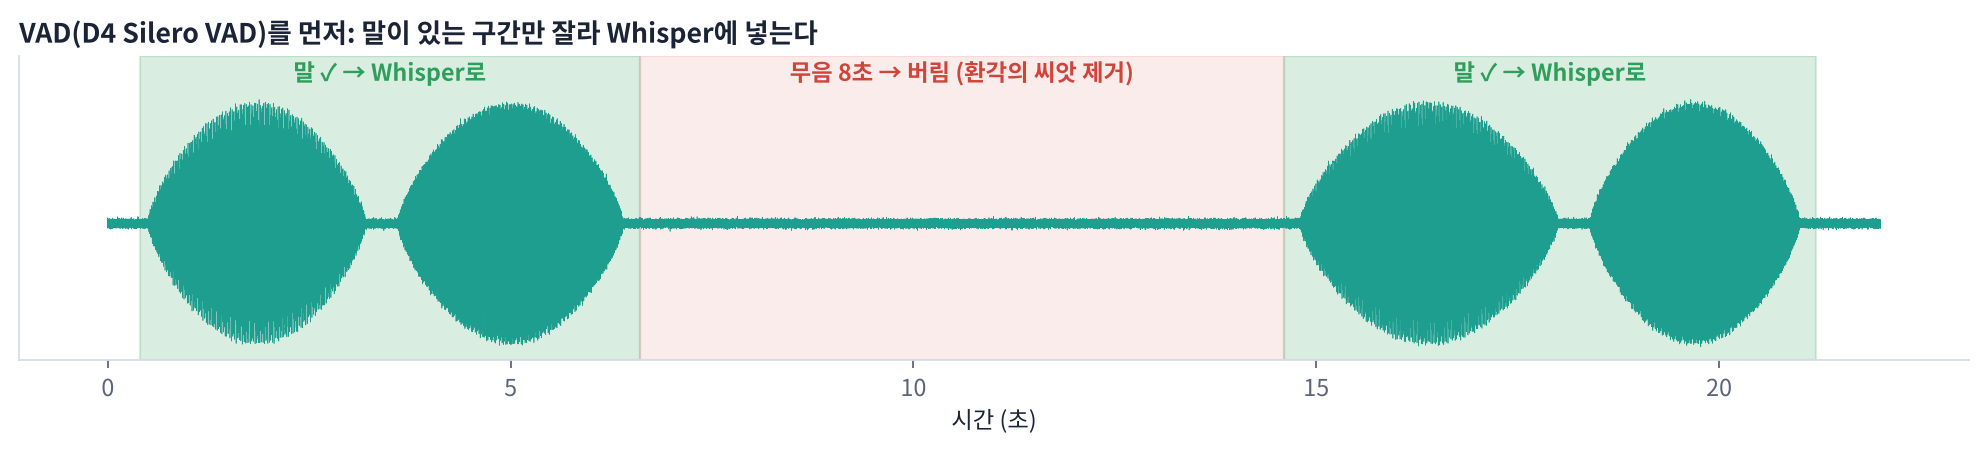

👣 **한 단계씩**
1. Silero VAD로 '말 구간'(시작, 끝)을 찾습니다.
2. 구간 앞뒤로 0.2초씩 여유를 두고 잘라 냅니다 (말 첫소리가 잘리지 않게).
3. 구간마다 받아 적고 이어 붙입니다. 무음 10초는 **아예 Whisper에 들어가지 않습니다.**

덤으로 **빨라집니다.** 들을 필요 없는 무음을 계산하지 않기 때문입니다. 실무 파이프라인(WhisperX, faster-whisper의 `vad_filter`)도 대부분 이 방식을 씁니다.

In [ ]:
from silero_vad import load_silero_vad, get_speech_timestamps

vad = load_silero_vad()
ts = get_speech_timestamps(torch.from_numpy(long_y), vad, sampling_rate=SR, min_silence_duration_ms=400)
PAD = int(0.2 * SR)
segments = [(max(0, t["start"] - PAD), min(len(long_y), t["end"] + PAD)) for t in ts]
print(f"VAD가 찾은 말 구간 {len(segments)}개:", [(round(a / SR, 1), round(b / SR, 1)) for a, b in segments])
speech_sec = sum(b - a for a, b in segments) / SR
print(f"Whisper에 넣는 길이: {speech_sec:.1f}초 / 전체 {len(long_y) / SR:.1f}초 ({speech_sec / (len(long_y) / SR):.0%})")

t0 = time.time()
vad_text = " ".join(transcribe(long_y[a:b], language="ko") for a, b in segments)
t_vad = time.time() - t0
print(f"\n[VAD → Whisper] {t_vad:.1f}초 | CER {jiwer.cer(norm(ref_long), norm(vad_text)):6.1%}\n{vad_text}")

fig, ax = plt.subplots(figsize=(13, 2.6))
ax.plot(np.arange(len(long_y)) / SR, long_y, lw=0.3, color="tab:cyan")
for a, b in segments:
    ax.axvspan(a / SR, b / SR, color="tab:green", alpha=0.2)
ax.set_xlabel("time (s)"); ax.set_title("Silero VAD speech segments (green) -> only these go into Whisper"); plt.tight_layout(); plt.show()

### 5-6. 환각 대응 체크리스트

| ✅ | 할 일 | 막는 환각 |
|---|---|---|
| ☐ | 서비스 언어를 알면 **`language=` 고정** | ④ 언어 · 작업 혼동 |
| ☐ | **VAD로 말 구간만** 넣기 (가장 효과 큼) | ① 무음 · ③ 프롬프트 베끼기 |
| ☐ | 긴 음성은 **안전장치 세트** (`temperature` 사다리 · `compression_ratio_threshold` · `logprob_threshold` · `no_speech_threshold`) | ① · ② |
| ☐ | 환각이 걱정되면 **`condition_on_prev_tokens=False`** | ② 반복 고리 전염 |
| ☐ | 프롬프트는 **짧게, 받아 쓴 문장처럼** | ③ |
| ☐ | 결과 후처리: "시청해 주셔서 감사합니다"처럼 **자주 나오는 환각 문장 목록**과 비교해 경고 | ① |
| ☐ | 모델이 클수록 대체로 환각이 적음. 중요한 기록은 **사람이 한 번 확인** | 전부 |

**❓ 생각해 보기**: 병원 진료 녹음을 자동 기록하는 서비스를 만듭니다. 환각이 특히 위험한 이유와, 위 체크리스트 중 반드시 넣을 것 세 가지는?

<details>
<summary>답 보기</summary>

진료 기록에 **실제로 하지 않은 말**(약 이름, 증상)이 들어가면 의료 사고로 이어질 수 있습니다. 진료실은 침묵 · 기계음이 많아 유형 ①이 잘 생깁니다. 반드시: **VAD로 무음 제거**, **안전장치 세트(무음 확률 · 확신 기준)**, **사람(의료진)의 최종 확인**. 추가로 **원본 녹음을 함께 보관**해 언제든 대조할 수 있게 합니다. 실제로 Whisper 기반 의료 받아쓰기에서 환각 사례가 보고된 적이 있습니다.

</details>

---
### 📝 4교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 4교시 탭](https://imguru-mooc.github.io/AI_Voice/day07/worksheet.html)** — 환각의 원인(자막 학습 · 언어 모델), 네 가지 유형, `<|nospeech|>` 확률과 0.6 기준, 압축률과 2.4 기준(transformers 1.35), 평균 확신 −1.0, temperature fallback 순서, 이전 문장 참고의 장단점, VAD 먼저
>
> 10문항을 풀고 **채점하기**를 누르세요. 결과 코드와 해설이 나옵니다. 채점 후에는 답이 잠깁니다. 4교시까지 마쳤다면 아래 Part 6의 **제출 방법**을 따라 노션에 제출하세요.

## Part 6. 정리 & 과제

### 오늘 배운 것
| 개념 | 한 줄 정리 | 코드 |
|---|---|---|
| 구조 | 귀(Encoder)가 30초를 한 번 듣고, 손(Decoder)이 한 토큰씩 적음 | `model.model.encoder`, `generate()` |
| 30초 창 | 짧으면 0으로 채우고, 길면 잘림. Log-Mel 80 × 3000 → 1500칸(20 ms) | `proc(...).input_features` |
| 특수 토큰 | 시작 · 언어 · 할 일 · 타임스탬프 = 주문서 | `language=`, `task=` |
| 모델 크기 | tiny ~ large-v3, turbo = Decoder 4층 | RTF = 걸린 시간 ÷ 음성 길이 |
| 언어 감지 | SOT 다음 토큰에서 언어 99개의 확률 | `logits[0, -1, LANG_IDS].softmax(-1)` |
| 번역 | 어떤 언어 → **영어**만. turbo는 X | `task="translate"` |
| greedy · beam | 1등만 vs 후보 여러 줄 | `num_beams=5` |
| temperature | 점수를 T로 나눠 확률을 퍼뜨림, 막혔을 때 탈출용 | `do_sample=True, temperature=0.6` |
| 타임스탬프 | 0.02초 간격 시각 토큰, 구간 단위 | `return_timestamps=True` |
| 프롬프트 | 용어 쪽지. 무음에서는 베끼기 위험 | `proc.get_prompt_ids(...)` |
| 환각 대응 | VAD 먼저 + 무음 확률 + 압축률 + fallback | `no_speech_threshold`, `compression_ratio_threshold` |

### 📝 과제
1. **내 목소리 비교**: 휴대폰으로 30초 안팎의 한국어 설명(전문 용어 3개 이상 포함)을 녹음해 tiny · small · (가능하면) turbo로 받아 적고, RTF · CER · 틀린 단어를 표로 정리하세요. 정답 문장은 직접 적습니다.
2. **환각 사냥**: 1분 이상의 음성(회의 · 강의 녹음, 중간에 침묵 · 음악 포함)을 골라 ① 안전장치 없음 ② 안전장치 세트 ③ VAD 먼저, 세 가지로 받아 적고 **환각이 생긴 곳과 사라진 곳**을 표시하세요.
3. **설계 메모 (반 페이지)**: "공장 현장 안전 점검을 음성으로 보고하는 앱"에 Whisper를 쓴다면 모델 크기, `language`, 프롬프트에 넣을 용어, 환각 대응을 어떻게 정할지 오늘 표를 근거로 쓰세요.

### ✅ 개념 워크시트 제출
4교시 탭까지 모두 채점했다면 오늘 내용을 정리해 제출합니다.

> 📝 **[D7 개념 워크시트 열기](https://imguru-mooc.github.io/AI_Voice/day07/worksheet.html)** — 4교시 × 10문항 (객관식 5 · OX 2 · 선잇기 1 · 순서 맞추기 1 · 모두 고르기 1)

**제출 방법 (노션)**
1. 4개 교시 탭을 모두 채점합니다.
2. **제출** 버튼을 눌러 오답 정리를 엽니다.
3. **📋 캡처 (노션용 복사)**를 누른 뒤, 노션 제출 페이지에서 `Ctrl + V`로 붙여 넣습니다. 이름, 교시별 점수, 오답 표(내 답과 정답)가 함께 붙습니다.

> 🎬 복습용: [애니메이션 전체 보기](https://imguru-mooc.github.io/AI_Voice/day07/animation.html) — D7-1 ~ D7-9

### 다음 시간 (D8)
오늘 확인한 것: Whisper는 **30초를 다 계산**하고, **Decoder가 토큰마다 반복**해서 느립니다. D8에서는 이것을 빠르게 만듭니다. **faster-whisper**(CTranslate2), **whisper.cpp**, **양자화**(int8), 그리고 말하는 도중에 자막을 띄우는 **청크 기반 스트리밍 인식**입니다. 오늘의 VAD와 안전장치가 그대로 다시 나옵니다.